# Analisi concentrazione Ostreopsis ovata 
Ostreopsis Ovata è una microalga unicellulare bentonica, rintracciabile  prevalentemente nei mesi estivi, dato che le fioriture sono frequentemente correlate al superamento di determinate soglie termiche dell'acqua

Originaria di acque tropicali e subtropicali, da circa 20 anni è diffusa anche nel Mediterraneo. 

Durante le fioriture produce tossine che possono causare disturbi respiratori nei bagnanti e recare danni agli organismi marini.

Pertanto è fondamentale monitorarne la concentrazione lungo le coste, in particolare la soglia critica si ha una volta superate le 10.0000 cell/L, mentre lo stato di emergenza si dichiara in seguito al superamento di > 30.000 cell/L 



I campionamenti effettuati si dividono tra misure effettuate nella zona di fondo e nella colonna d'acqua.
Dato che è una specie bentonica predilige substrati rigidi e acque profonde, quindi anche zone diverse della stessa costa presenteranno concentrazioni molto differenti. 

Analizziamone la concentrazione in diversi siti della provincia di Brindisi  per capire se le fioriture siano un fenomeno localizzato o se si disperda lungo l'intera costa.


In [14]:
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import numpy as np

path=r'C:\\Users\\sofia\\Università\\Tirocinio\\Dati ARPA\\Arpa_Puglia_dataset\\Dataset_Ostreopsis-Aliena_2014-2023.xlsx'
df_ost = pd.read_excel(path, header=2, sheet_name=1)
# Rimuoviamo le colonne senza nome
df_ost = df_ost.loc[:, ~df_ost.columns.str.contains('^Unnamed')]

display(df_ost)

,ANNO,Data,PROVINCIA,SITO,QUOTA,Densità Ostreopsis ovata (cell/L)
0,2014,2014-06-13,BR,APANI LIDO S.VINCENZO (BR),Acque fondo,500
1,2014,2014-06-13,BR,APANI LIDO S.VINCENZO (BR),Acque colonna,320
2,2014,2014-06-26,BR,APANI LIDO S.VINCENZO (BR),Acque fondo,200
3,2014,2014-06-26,BR,APANI LIDO S.VINCENZO (BR),Acque colonna,120
4,2014,2014-07-10,BR,APANI LIDO S.VINCENZO (BR),Acque fondo,400
...,...,...,...,...,...,...
475,2023,2023-08-17,BR,TORRE CANNE DI FRONTE AL FARO (BR),Acque colonna,79
476,2023,2023-09-12,BR,TORRE CANNE DI FRONTE AL FARO (BR),Acque fondo,3611
477,2023,2023-09-12,BR,TORRE CANNE DI FRONTE AL FARO (BR),Acque colonna,0
478,2023,2023-09-22,BR,TORRE CANNE DI FRONTE AL FARO (BR),Acque fondo,152251


### Biovolume

Esprimiamo  la concentrazione dell'alga in funzione del **Biovolume ($\mu\text{m}^3/\text{L}$)**, ovvero lo spazio tridimensionale occupato dalle cellule nell'acqua

La conversione da cell/L a $\mu\text{m}^3/\text{L}$ avviene moltiplicando la concentrazione di cell/L per il **biovolume medio** della cell e per la **densità cellulare**

Dati della letturatura riportano il valore di biovolume medio della cellula di Ostreopsis ovata pari a  $V \approx 30.000 \ \mu\text{m}^3$

Esprimiamo le soglie critiche in termini di biovolume: 

In [15]:
#calcolo soglie critiche
soglia_allarme = 10000*30000
soglia_critica = 30000*30000
print("Soglia allarme:", soglia_allarme, "µm³/L")
print("Soglia critica:", soglia_critica, "µm³/L")

Soglia allarme: 300000000 µm³/L
Soglia critica: 900000000 µm³/L


## Analisi dati dei parametri ambientali 

Verifichiamo dai valori dei data raccolti dal monitoraggio se esistono associazioni tra l'andamento della concentrazione di Ostreopsis ovata e le condizioni ambientali


**PARAMETRI CHIMICO-FISICI**
- **Temperatura (°C)**: associata alla stagionalità + alle condizioni favorevoli di crescita dell'alga. 
    +  regola la solubilità dei gas discolti in acqua 
    + problema: un suo aumento riduce la capacità dell'acqua di trattenere O2 & fav la proliferazione di specie aline/alghe tossiche
     
- **Ossigeno Disciolto (OD)**
    la sua analisi può fornire informazioni sulle condizioni dell'acqua e sui processi biologici
    + problema: ipossia se < 2 mg/L o anossia quando OD=0 

- **Salinità (PSU‰)**: conc dei sali disciolti 
    + problema: stratificazione delle masse d'acqua 
    (acqua + salata =  + densa = meno ricambi = meno ricircolo di nutrienti)

- **pH**: valori ottimali tra 7.8 - 8.2
    + può variare in relazione ai processi biologici e alle condizioni chimiche dell'acqua
    problema: acidificazione (valori elevati corrispondono a una magg quantità di CO2 disciolta) VS valori troppo bassi impediscono la precipitazione dei carbonati (quindi la formazione di gusci per gli organismi)

**NUTRIENTI**
- **Azoto (N-NO3, N-NH4) e Fosforo (P-PO4)** indicatori della disponibilità di nutrienti 
    + problema: eccesso causa eutrofizzazione 

- **Clorofilla ($\mu\text{g/L}$)**: indicatore della biomassa fitoplanctonica 
    + problema: livelli elevati indici di un boom algale
    
- **Torbidità**: legata alla presenza di solidi disciolti determina la quantità di luce che riesce a penetrare la colonna d'acqua
    problema: se elevata riduce la fotosintesi 



In [16]:
#Carichiamo i dati del 2°foglio Excel     #sheet_name=1 indica che vogliamo leggere il secondo foglio del file Excel (l'indice parte da 0)
df_cis= pd.read_excel(r"C:\Users\sofia\Università\Tirocinio\Dati ARPA\Arpa_Puglia_dataset\Dataset_CIS-Aliena-2014-2023.xlsx", sheet_name=1, header=2)  #header=2 indica che vogliamo leggere i dati a partire dalla riga 3 (l'indice parte da 0) e che la riga 3 contiene i nomi delle colonne

# .iloc[:-2] rimuove le ultime due righe del df (sono righe vuote che non contengono dati)
df_cis = df_cis.iloc[:-2]

print(f"caricati{len(df_cis)} record validi")

#in ambiente Jupyter Notebook scrivendo semplicemnte il nome della variabile come ultima istruzione della cella Pandas genera automaticamnte la tabella formattata in HTML (vd sotto)
df_cis


caricati908 record validi


,Data,Categoria,Corpo Idrico Superficiale,Descrizione,Codice Stazione,Quota prelievo,Altezza colonna d'acqua (m),Trasparenza (m),Temperatura (°C),Salinità (PSU),...,Ossigeno disciolto (% saturazione),Ossigeno disciolto (O2) (mg/l),Clorofilla (µg/l),Silicio da ortosilicati (Si-SiO4) (µg/l),Azoto totale (N) (µg/l),Azoto ammoniacale (N-NH4) (µg/l),Azoto nitroso (N-NO2) (µg/l),Azoto nitrico (N-NO3) (µg/l),Fosforo totale (P) (µg/l),Fosforo da ortofosfato (P-PO4) (µg/l)
0,2014-01-10 00:00:00,MC,Area Marina Protetta Torre Guaceto,T_Guaceto_500,MC_TG01,SUPERFICIE,0.5,FONDO,14.04,37.83,...,114.38,9.25,0.26,55,158,23.54,10.48,109.16,8.89,<5
1,2014-01-10 00:00:00,MC,Area Marina Protetta Torre Guaceto,T_Guaceto_500,MC_TG01,FONDO,5.0,NaN,14.07,37.87,...,111.98,9.05,0.38,46,90,12.04,<2,26.91,<5,<5
2,2014-01-10 00:00:00,MC,Area Marina Protetta Torre Guaceto,T_Guaceto_1750,MC_TG02,SUPERFICIE,0.5,8,14.33,38.02,...,113.18,9.08,0.64,106,70,27.87,<2,9.48,<5,<5
3,2014-01-10 00:00:00,MC,Area Marina Protetta Torre Guaceto,T_Guaceto_1750,MC_TG02,FONDO,38.0,NaN,15.23,38.5,...,100.28,7.72,0.47,56,69,9.1,2.2,3.87,11.24,<5
4,2014-02-14 00:00:00,MC,Area Marina Protetta Torre Guaceto,T_Guaceto_500,MC_TG01,SUPERFICIE,0.5,FONDO,13.96,38.08,...,110.38,8.94,0.19,83,112,18.53,<2,24.41,17.73,<5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
903,2023-10-26 00:00:00,MC,Torre Canne Limite nord AMP Torre Guaceto,Villanova_1750,MC_VL02,FONDO,29.0,20,21.96,38.5,...,115.80,8.08,0.35,64,292,<10,<2,7.5,9.7,7
904,2024-01-16 00:00:00,MC,Torre Canne Limite nord AMP Torre Guaceto,Villanova_500,MC_VL01,SUPERFICIE,0.5,14.8,13.66,37.7,...,91.60,7.53,0.16,175,76.446,<10,6.4,16.272,5.7,5.5
905,2024-01-16 00:00:00,MC,Torre Canne Limite nord AMP Torre Guaceto,Villanova_1750,MC_VL02,SUPERFICIE,0.5,8.5,13.60,37.7,...,93.50,7.70,0.33,162,66,<10,7.1,13,5.5,<5
906,2024-01-16 00:00:00,MC,Torre Canne Limite nord AMP Torre Guaceto,Villanova_1750,MC_VL02,FONDO,27.0,8.5,14.16,38,...,94.80,7.70,0.49,160,68,<10,4.2,15,<5,<5


Ora uniamo a questa tabella quella coi valori relativi alla concentrazione di Ostreopsis ovata, così da avere un unico grande daset da cui attingere le informazioni 

Per farlo dobbiamo fare un'azione di **join** delle due tabelle tramite un **parametro comune**: la vicinanza delle stazioni a dove sono stati presi i valori dei parametri dell'acqua & il momento delle misurazioni



In [17]:
#Carichiamo il df con le concentrazioni di Ostreopis ovata
df_ost=pd.read_excel(r'C:\Users\sofia\Università\Tirocinio\Dati ARPA\Arpa_Puglia_dataset\Dataset_Ostreopsis-Aliena_2014-2023.xlsx', header=2, sheet_name=1)
# Rimuoviamo le colonne senza nome
df_ost = df_ost.loc[:, ~df_ost.columns.str.contains('^Unnamed')]

#preparazione dati df_ost
df_ost['Data']= pd.to_datetime(df_ost['Data'], errors='coerce')
# .astype(str).str.strip() converte i valori della colonna in stringhe e rimuove eventuali spazi bianchi in modo da evitare errori di confronto causati da differenze di formattazione
df_ost['SITO'] = df_ost['SITO'].astype(str).str.strip()

#Visualizziamo la densità della microalga in termini di biovolume 
df_ost['Densità Ostreopsis ovata (cell/L)'] = pd.to_numeric(df_ost['Densità Ostreopsis ovata (cell/L)'], errors='coerce')
Biovolume_cellulare = 30000
df_ost['Biovolume (µm3/L)'] = df_ost['Densità Ostreopsis ovata (cell/L)'] * Biovolume_cellulare

#associamo la stazione di Ostreopis con la stazione più vicina della reta di monitaraggio CIS 
site_to_cis_map = {
    'APANI LIDO S.VINCENZO (BR)': 'MC_TG01',
    'TORRE CANNE DI FRONTE AL FARO (BR)': 'MC_VL01',
    'LA FORCATELLA PRIMA CASA BIANCA (BR)': 'MC_VL01',
}

#eliminiamo eventuali spazi bianchi in modo che colonne con la stessa intestazione non vengano mechate
df_cis.columns=(df_cis.columns.str.replace('\u00a0',' ', regex=False).str.replace(r'\s+',' ',regex=True).str.strip())
        #.str.replace() rimuove  agli argomenti e li sostituisce col secondo argomento
            #(\u00a0 sono spazi non visibili da excel che vengono rimossi e sostituiti con spazi visibili
            #(\s+) è un'espressione regolare che rappresenta uno o più spazi bianchi consecutivi, e li sostituisce con un singolo spazio
        #.str.strip() rimuove eventuali spazi bianchi all'inizio e alla fine dei nomi delle colonne



#creiamo una nuova colonna nel df_cis che contenga il nome della stazione Ost e il biovolume 
df_ost['Codice stazione'] = df_ost['SITO'].map(site_to_cis_map)

#preparazione df_cis
df_cis['Data']=pd.to_datetime(df_cis['Data'], errors='coerce')
df_cis = df_cis.sort_values('Data').copy()
df_cis['Temperatura (°C)'] = pd.to_numeric(df_cis['Temperatura (°C)'], errors='coerce')



#Rinominazione colonna per uniformare i nomi delle colonne tra i due df e facilitare il merge 
df_ost = df_ost.rename(columns={'QUOTA': 'Quota prelievo'})

# Normalizziamo i nomi delle colonne per evitare errori dovuti a spazio/maiuscole
df_cis['Codice stazione'] = df_cis['Codice Stazione'].astype(str).str.strip()
df_cis['Quota prelievo'] = df_cis['Quota prelievo'].astype(str).str.strip().str.upper()

# Uniformiamo la quota nel df_ost al formato del CIS (FONDO/SUPERFICIE)
quota_map = {'Acque fondo': 'FONDO', 'Acque colonna': 'SUPERFICIE'}
df_ost['Quota prelievo'] = df_ost['Quota prelievo'].astype(str).str.strip().map(quota_map)

# selezioniamo solo le colonne di interesse nel df_cis e ne creiamo una copia + applichiamo dropna per evitare celle vuote/NaN  
df_cis = df_cis[['Data',
                'Codice stazione',
                'Quota prelievo',
                'Temperatura (°C)',
                'Salinità (PSU)',
                'pH (unità)',
                'Ossigeno disciolto (O2) (mg/l)',
                'Clorofilla (µg/l)',
                'Azoto totale (N) (µg/l)',
                'Azoto ammoniacale (N-NH4) (µg/l)',
                'Azoto nitrico (N-NO3) (µg/l)',
                'Fosforo totale (P) (µg/l)'
                ]].dropna(subset=['Data', 'Codice stazione','Quota prelievo']).copy()
                    #.dropna(subset=[]) richiede che queste variabili siano presenti e non siano NaN per poter effettuare il merge, se manca una sola delle variabili viene eliminata la riga
                          #per effettuare il merge è sufficiente che le colonne chiave non siano NaN (Data, codice stazione, quota prelievo)  

# Parametri ambientali da controllare 
parametri_cis = [
    'Temperatura (°C)',
    'Salinità (PSU)',
    'pH (unità)',
    'Ossigeno disciolto (O2) (mg/l)',
    'Clorofilla (µg/l)',
    'Azoto totale (N) (µg/l)',
    'Azoto ammoniacale (N-NH4) (µg/l)',
    'Azoto nitrico (N-NO3) (µg/l)',
    'Fosforo totale (P) (µg/l)'
]       

for colonna in parametri_cis:
    # Converto i valori in stringhe e rimuovo eventuali spazi
    valori = df_cis[colonna].astype('string').str.strip()
    # Sostituisco ogni valore <X con X/2
    valori = valori.str.replace(
        r'^<\s*(\d+(?:[.,]\d+)?)$',
        lambda x: str(float(x.group(1).replace(',', '.')) / 2),
        regex=True
    )
    # Sostituisco eventuali virgole decimali con punti
    valori = valori.str.replace(',', '.', regex=False)
    # Converto in numerico; N.D. diventa NaN
    df_cis[colonna] = pd.to_numeric(valori, errors='coerce')


#ordino i df in base alle rispettive date
df_cis = df_cis.sort_values('Data')
df_ost = df_ost.dropna(subset=['Data','SITO','Codice stazione','Quota prelievo']).sort_values('Data')
#Rinomian le colonne delle date per vedere la distanza temporale tra i campionamenti dell'alga e dell'acqua
df_ost = df_ost.rename(columns={'Data': 'Data_ost'})
df_cis = df_cis.rename(columns={'Data': 'Data_CIS'})
# Verifico e uniformo il formato delle date
df_ost['Data_ost'] = pd.to_datetime(df_ost['Data_ost'], errors='coerce')
df_cis['Data_CIS'] = pd.to_datetime(df_cis['Data_CIS'], errors='coerce')


df = pd.merge_asof(
    df_ost,
    df_cis,
    left_on='Data_ost',
    right_on='Data_CIS',
    by=['Codice stazione', 'Quota prelievo'],
    direction ='nearest',
    tolerance= pd.Timedelta(days=30)
)

#Calcoliamo la distanza temporale tra i campionamenti 
df['Distanza temporale (giorni)'] = (df['Data_ost'] - df['Data_CIS']).dt.days.abs().astype('Int64')


# Riordino colonne in modo che sia più intuitiva la visualizzazione
    #a. lista colonne df
columns = df.columns.tolist()
    # b. lista delle colonne da spostare
columns_to_move = [
    'Codice stazione',
    'Quota prelievo',
    'Data_ost',
    'Data_CIS',
    'Distanza temporale (giorni)'
]
    #c. ciclo for in cui scorriamo la lista delle colonne da spostare 
for col in columns_to_move:
    #d. rimuovo la corrispondente colonna dalla lista delle colonne del df
    columns.remove(col)     
    #e. trova la posizione della colonna 'SITO', aggiungendo +1 individua la posizione sucesiva
pos = columns.index('SITO') + 1
    #e. la inserisce  nella posizione trovata
columns[pos:pos] = columns_to_move
    #f. riordina il df secondo la nuova lista di colonne
df = df[columns]

display(df)


,ANNO,PROVINCIA,SITO,Codice stazione,Quota prelievo,Data_ost,Data_CIS,Distanza temporale (giorni),Densità Ostreopsis ovata (cell/L),Biovolume (µm3/L),Temperatura (°C),Salinità (PSU),pH (unità),Ossigeno disciolto (O2) (mg/l),Clorofilla (µg/l),Azoto totale (N) (µg/l),Azoto ammoniacale (N-NH4) (µg/l),Azoto nitrico (N-NO3) (µg/l),Fosforo totale (P) (µg/l)
0,2014,BR,APANI LIDO S.VINCENZO (BR),MC_TG01,FONDO,2014-06-13,2014-06-24,11,500,15000000,22.12,37.65,8.11,8.34,0.01,149.0,14.1,29.6,2.5
1,2014,BR,APANI LIDO S.VINCENZO (BR),MC_TG01,SUPERFICIE,2014-06-13,2014-06-24,11,320,9600000,22.66,37.49,8.07,8.38,0.01,175.0,19.0,35.9,2.5
2,2014,BR,TORRE CANNE DI FRONTE AL FARO (BR),MC_VL01,SUPERFICIE,2014-06-13,2014-05-28,16,0,0,20.33,37.21,8.06,5.75,0.02,184.0,36.1,28.7,5.4
3,2014,BR,TORRE CANNE DI FRONTE AL FARO (BR),MC_VL01,FONDO,2014-06-13,2014-05-28,16,200,6000000,19.52,37.63,8.11,5.75,0.3,253.0,86.3,22.8,2.5
4,2014,BR,LA FORCATELLA PRIMA CASA BIANCA (BR),MC_VL01,FONDO,2014-06-13,2014-05-28,16,200,6000000,19.52,37.63,8.11,5.75,0.3,253.0,86.3,22.8,2.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,2023,BR,LA FORCATELLA PRIMA CASA BIANCA (BR),MC_VL01,SUPERFICIE,2023-09-22,NaT,<NA>,953,28590000,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
476,2023,BR,LA FORCATELLA PRIMA CASA BIANCA (BR),MC_VL01,FONDO,2023-09-22,NaT,<NA>,80089,2402670000,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
477,2023,BR,TORRE CANNE DI FRONTE AL FARO (BR),MC_VL01,FONDO,2023-09-22,NaT,<NA>,152251,4567530000,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
478,2023,BR,APANI LIDO S.VINCENZO (BR),MC_TG01,SUPERFICIE,2023-09-22,NaT,<NA>,0,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


Analizziamo se il merge è riuscito ad abbinare i valori e quale mancata corrispondenza ha generato i valori nulli (NaN)

+Valutiamo come si distribuiscono i campionamenti tra le diverse stazioni di monitoraggio e quote di prelievo


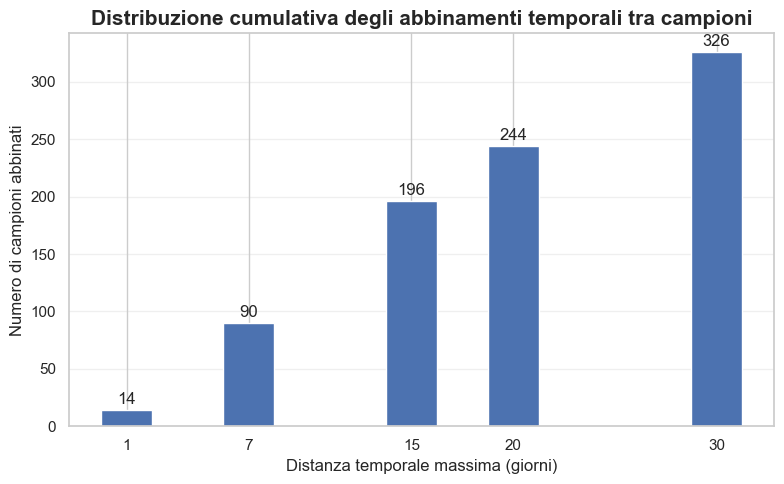

------------------------------------------------------------------------------------------------------------------------------------------------


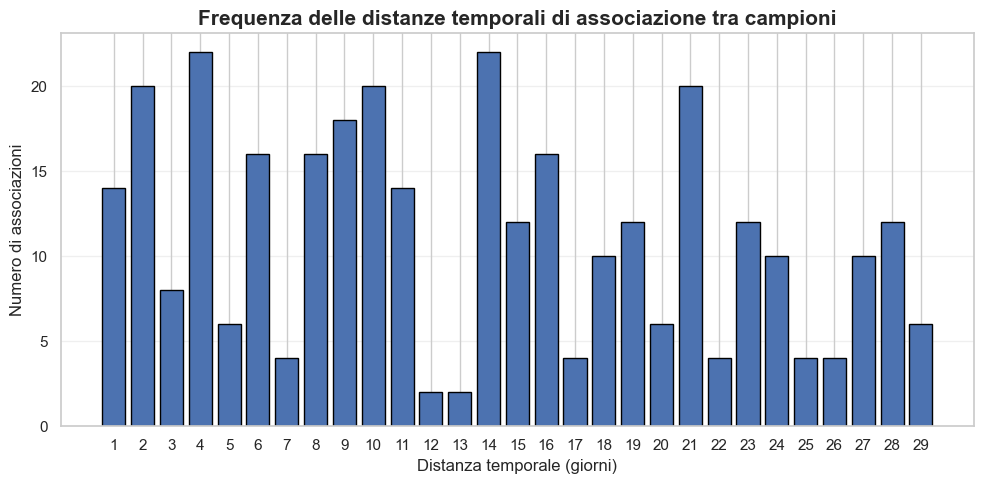

------------------------------------------------------------------------------------------------------------------------------------------------
Campioni senza corrispondenza CIS: 154
Campioni abbinati senza parametri ambientali: 0

Distanza temporale (giorni):
count        326.0
mean     13.380368
std       8.213466
min            1.0
25%            6.0
50%           14.0
75%          20.75
max           29.0
Name: Distanza temporale (giorni), dtype: Float64
Abbinamenti entro 1 giorni: 14
Abbinamenti entro 7 giorni: 90
Abbinamenti entro 15 giorni: 196
Abbinamenti entro 20 giorni: 244
Abbinamenti entro 30 giorni: 326
------------------------------------------------------------------------------------------------------------------------------------------------

Campioni totali di Ostreopsis ovata, suddivisi per stazione e quota:
Codice stazione  Quota prelievo
MC_TG01          FONDO              80
                 SUPERFICIE         80
MC_VL01          FONDO             160
           

In [18]:
#definiamo la lista dei parametri ambientali da considerare 
parametri = [
    'Temperatura (°C)',
    'Salinità (PSU)',
    'pH (unità)',
    'Ossigeno disciolto (O2) (mg/l)',
    'Clorofilla (µg/l)',
    'Azoto totale (N) (µg/l)',
    'Azoto ammoniacale (N-NH4) (µg/l)',
    'Azoto nitrico (N-NO3) (µg/l)',
    'Fosforo totale (P) (µg/l)'
]

giorni = [1, 7, 15, 20, 30]

campioni_abbinati = [df['Distanza temporale (giorni)'].le(g).sum()for g in giorni]
plt.figure(figsize=(8, 5))
plt.bar(giorni, campioni_abbinati, width=2.5)
plt.xlabel('Distanza temporale massima (giorni)')
plt.ylabel('Numero di campioni abbinati')
plt.title('Distribuzione cumulativa degli abbinamenti temporali tra campioni', fontsize=15, fontweight='bold')
plt.xticks(giorni)
plt.grid(axis='y', alpha=0.3)

# Inseriamo il numero sopra ogni barra
for x, y in zip(giorni, campioni_abbinati):
    plt.text(x, y + 5, str(y), ha='center')

plt.tight_layout()
plt.show()

print("------------------------------------------------------------------------------------------------------------------------------------------------")

#calcoliamo la distanza effettiva
distanze = df['Distanza temporale (giorni)'].dropna()

plt.figure(figsize=(10, 5))
frequenze = distanze.value_counts().sort_index()

plt.bar(
    frequenze.index,
    frequenze.values,
    width=0.8,
    edgecolor='black'
)

plt.xlabel('Distanza temporale (giorni)')
plt.ylabel('Numero di associazioni')
plt.title('Frequenza delle distanze temporali di associazione tra campioni', fontsize=15, fontweight='bold')

plt.xticks(range(1, 30))
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()



print("------------------------------------------------------------------------------------------------------------------------------------------------")
# Quante righe non hanno trovato un campione CIS?
print("Campioni senza corrispondenza CIS:",df['Data_CIS'].isna().sum())  #isna() controlla se un valore è mancante (restituisce True nel caso sia NaN)     
                                   #sum() conta le volte in cui la condizione è vera (ovvero conta i valori che non trovano corrispondenza)
# Quante righe hanno trovato una corrispondenda temporale  ma per cui non sono disponibili parametri ambientali?
print( "Campioni abbinati senza parametri ambientali:",(df['Data_CIS'].notna() & df[parametri].isna().all(axis=1)).sum())
# Distribuzione delle distanze temporali 
print("\nDistanza temporale (giorni):")
    #.describe() fornisce statistiche descrittive sulla distribuzione dei dati
print(df['Distanza temporale (giorni)'].describe())

# Quanti campioni sono abbinati entro diverse distanze?
for giorni in [1, 7, 15, 20, 30]:
    n = (df['Distanza temporale (giorni)'].le(giorni) .sum())
    print(f"Abbinamenti entro {giorni} giorni: {n}")

print("------------------------------------------------------------------------------------------------------------------------------------------------")

#1. Capiamo quanti campioni totali di Ostreopsis erano presenti per ciascuna stazione e quota prima del merge
print("\nCampioni totali di Ostreopsis ovata, suddivisi per stazione e quota:")
  #groupby() raggruppa le righe in base alla combinazione tra stazione e quota --> serve per capire se l'abbinamento è analogo nelle 3 stazioni
              # dropna=False include anche i NaN       #.size() conta il numero di righe per gruppo
print(df.groupby(['Codice stazione', 'Quota prelievo'], dropna=False).size())

#2. Quanti campioni CIS hanno trovato corrispondenza per stazione e quota
print("\nCampioni che hanno trovato corrispondenza per stazione e quota:")  #\n serve per andare a capo e separare le due stampe
  #df['Data_CIS'].notna() individua le righe in cui è presente la data, quindi da quelle avviene il conteggio
print(df[df['Data_CIS'].notna()].groupby(['Codice stazione', 'Quota prelievo'], dropna=False).size())

print("\nCampioni Ostreopsis dove non è stata trovata corrispondenza per stazione e quota:")
#df['data_CIS'].isna  seleziona le righe in cui la colonna è mancante (NaN), quindi quelle dove non è stato possibile trovare corrispondenza
print(df[df['Data_CIS'].isna()].groupby(['Codice stazione', 'Quota prelievo'], dropna=False).size())

print("------------------------------------------------------------------------------------------------------------------------------------------------")
#verifico che i valori <x siano stati correttamemte convertiti in valori numerici 
for param in parametri_cis:
    valori = pd.to_numeric(df[param], errors='coerce')

    non_numerici = df[param].notna() & valori.isna()

    print(f"\n{param}")
    print("Valori non numerici:", non_numerici.sum())

    if non_numerici.sum() > 0:
        print(df.loc[non_numerici, param].unique())


#### Risultato del merge
Abbiamo associato ai campionamenti di Ostropis ovata i valori dei parametri ambientali appartenenti alle stazioni limitrofe per poter analizzare quali variabili influenzano l'aumento della concentrazione dell'alga nei mesi estivi. 

Appartenendo a reti di monitoraggio ARPA differenti, è stato necessario associare le misure di concentrazione dell'alga a quelle della stazione di analisi CIS più vicina, sulla base della quota di campionamento e della vicinanza temporale delle date di campionamento (utilizzando una tolleranza massima di 30 giorni). 

Su un totale di 480 campioni di Ostreopis ovata, 326 hanno trovato una corrispondenza (67.9%) con una distanza temporale media di 13 giorni

Abbiamo realizzato inoltre un grafico che permette di vedere immediatamente come aumenta il numero di campioni abbinati all'aumentare della tolleranza temporale

Essendo una funzione cumulativa ogni istogramma comprende anche tutti i campioni precedenti

# Analisi dell'andamento della concentrazione dell'alga in relazione ai parametri ambientali 

## Serie temporale 

### visualizzazione tramite grafico a istogrammi 

Creiamo un istogramma per ogni anno e per ogni quota di campionamento, in modo da avere una semplice comprensione del dato 

Per farlo occorre utilizzare la funzione di *Seaborn* 

    sns.barplot

La **media aritmetica** normalizza l'indice annuale

    estimator=np.mean
    
Innanzitutto verifichiamo la regolarità annua delle rilevazioni:


In [19]:
#verifico il numero di campionamenti per ciascun anno per sito e quota 

#Creazione della colonna Anno per verificare quante misurazioni sono state fatte 
df['ANNO']=df['Data_ost'].dt.year #.dt.year estrae l'anno dalla colonna 'Data' e lo assegna alla nuova colonna 'ANNO'

#groupby crea una tabella che raggruppa i dati per le colonne elencate e ne calcola il numero di misure di densità ['Densità].count()
    #unstack(level='ANNO') trasforma la colonna 'ANNO' in intestazioni di colonna separate per ciascun anno
conteggio_campioni= df.groupby(['SITO','Quota prelievo','ANNO'])['Densità Ostreopsis ovata (cell/L)'].count().unstack(level='ANNO')

print("NUMERO DI CAMPIONAMENTI PER CIASCUN ANNO")
display(conteggio_campioni)


NUMERO DI CAMPIONAMENTI PER CIASCUN ANNO


ANNO                                                 2014  2015  2016  2017  \
SITO                                 Quota prelievo                           
APANI LIDO S.VINCENZO (BR)           FONDO              8     8     8     8   
                                     SUPERFICIE         8     8     8     8   
LA FORCATELLA PRIMA CASA BIANCA (BR) FONDO              8     8     8     8   
                                     SUPERFICIE         8     8     8     8   
TORRE CANNE DI FRONTE AL FARO (BR)   FONDO              8     8     8     8   
                                     SUPERFICIE         8     8     8     8   

ANNO                                                 2018  2019  2020  2021  \
SITO                                 Quota prelievo                           
APANI LIDO S.VINCENZO (BR)           FONDO              8     8     8     8   
                                     SUPERFICIE         8     8     8     8   
LA FORCATELLA PRIMA CASA BIANCA (BR) FONDO              8     8     8     8   
                                     SUPERFICIE         8     8     8     8   
TORRE CANNE DI FRONTE AL FARO (BR)   FONDO              8     8     8     8   
                                     SUPERFICIE         8     8     8     8   

ANNO                                                 2022  2023  
SITO                                 Quota prelievo              
APANI LIDO S.VINCENZO (BR)           FONDO              8     8  
                                     SUPERFICIE         8     8  
LA FORCATELLA PRIMA CASA BIANCA (BR) FONDO              8     8  
                                     SUPERFICIE         8     8  
TORRE CANNE DI FRONTE AL FARO (BR)   FONDO              8     8  
                                     SUPERFICIE         8     8

### Realizzazione del grafico

per realizzare un grafico con 3 sottografici (uno per ciascuna stazione) occorre utilizzare: 

1.  **ciclo for**       
in modo che filtri la tabella e generi 3 grafici in sequenza 

      for sito in siti: 
        plt.figure()
        ax=plt.gca()
        sns.lineplot()
        ..


2.  **"sintassi orientata agli oggetti"** (Object Oriented)* di *Matplotlib*

    fig, (ax1 ax2, ax3) = plt.subplots(1,3, figsize())
    
Così invece che creare 3 grafici separati eseguendo lo script 3 volte creo un'unica finestra/figura contenente 3 sotto grafici (ax1, ax2, ax3) affiancati 

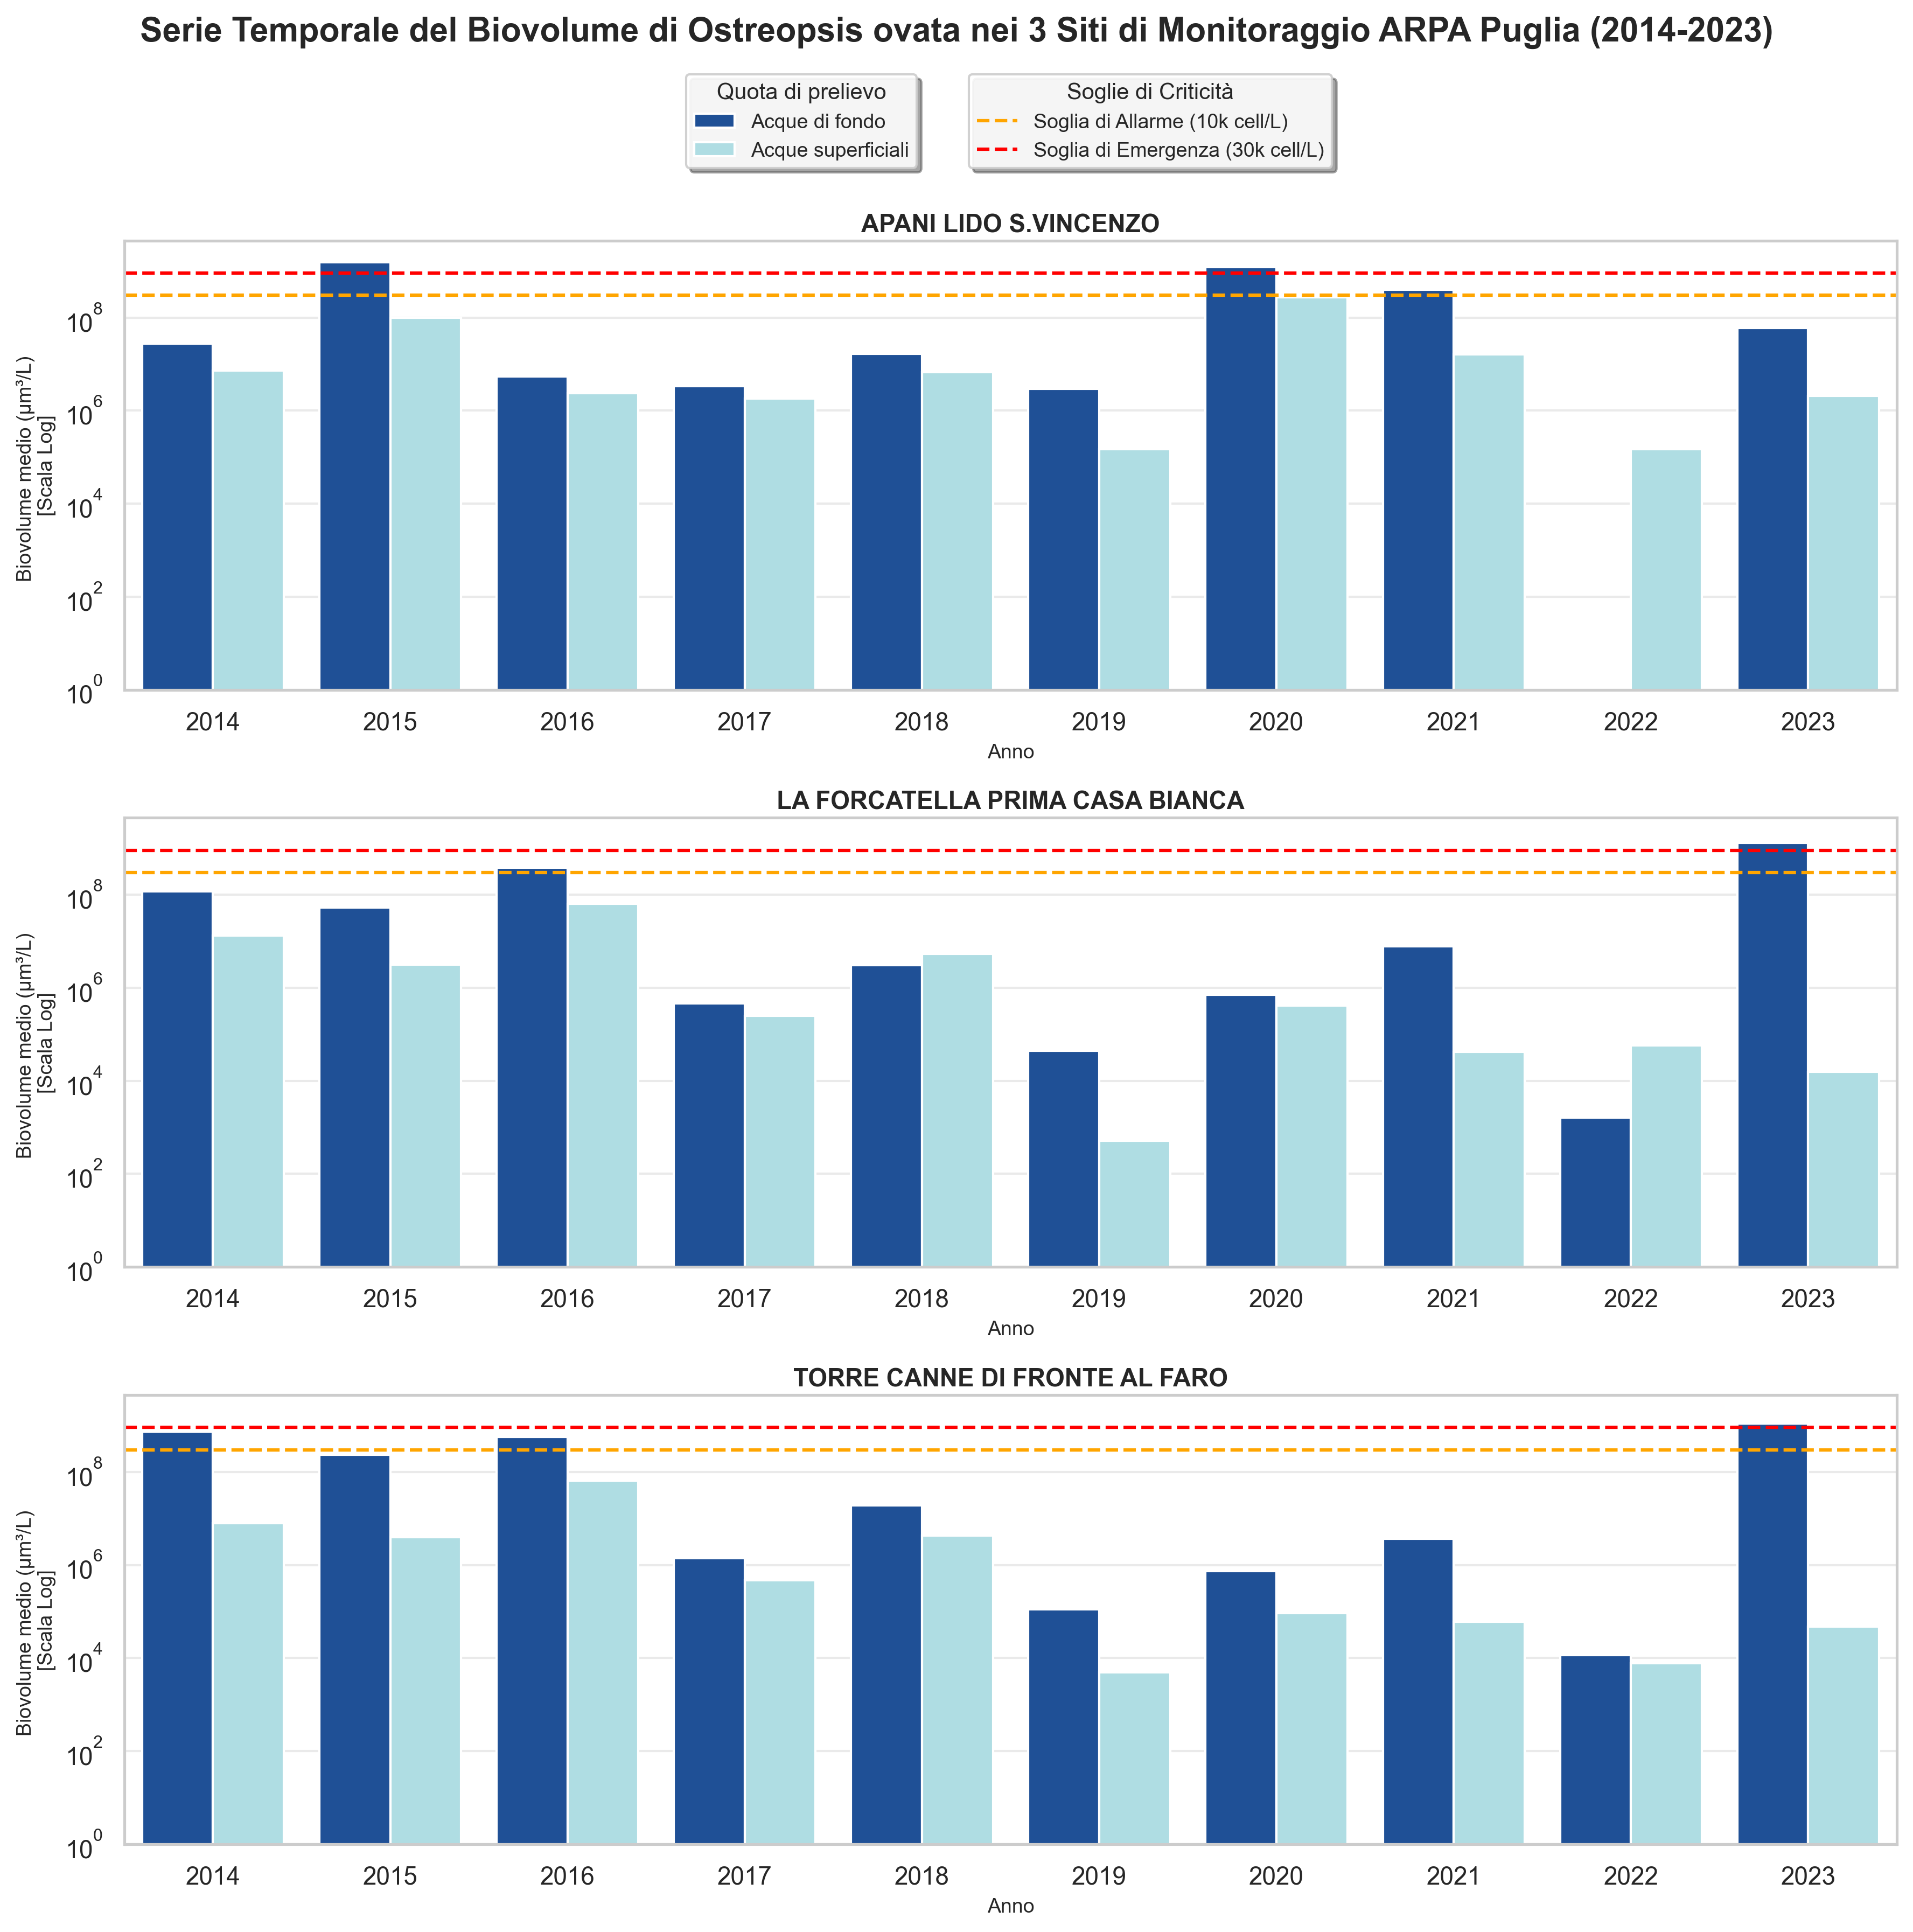

In [20]:

#preparazione dei dati (utilizziamo le date di campionamento prese quando è stata effettuata la misura della densità di Ostreopsis ovata)
df['Data_ost'] = pd.to_datetime(df['Data_ost'], format='%d/%m/%Y', errors='coerce')
df['Densità'] = pd.to_numeric(df['Densità Ostreopsis ovata (cell/L)'], errors='coerce').fillna(0)
df['ANNO']=df['Data_ost'].dt.year
# Calcolo del Biovolume (30.000 um³ per cellula)
BIOVOLUME_CELLULA = 30000
df['Biovolume µm3/L'] = df['Densità'] * BIOVOLUME_CELLULA

# Data l'ampiezza dei valori del Biovolume, conviene utilizzare una scala logaritmica
# Ma dato che per Densità = 0 cell --> log0= indefinito
# ==> sommiamo +1 a tutti i valori (quantità trascurabile dato l'elevato numero di cellule). Così l'asse y parte da 1 (10^0) e non da 0 (10^-∞)
df['Biovolume µm3/L'] = df['Biovolume µm3/L'] + 1

# Lista dei 3 siti
siti = [
    'APANI LIDO S.VINCENZO (BR)', 
    'LA FORCATELLA PRIMA CASA BIANCA (BR)', 
    'TORRE CANNE DI FRONTE AL FARO (BR)'
]

palette = {'FONDO': '#0B4DAA', 'SUPERFICIE': "#A6E4EC"}

# Creazione del grafico 
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 12), dpi=300, sharey=True)    #sharey=True fa sì che tutti e 3 i grafici abbiano la stessa scala sull'asse y
assi = [ax1, ax2, ax3]

#il ciclo for scorre la lista dei siti e crea un grafico per ciascuno
for i, sito in enumerate(siti):    # i,sito = variabili a cui enumerate() associa rispettivamente l'indice e il valore nella lista 'siti'
    ax = assi[i]   #[i] prende l'asse corrispondente al sito corrente (ax1, ax2 o ax3)
    df_sito = df[df['SITO'].str.contains(sito, na=False, regex=False)].sort_values('Data_ost')   #na=False non considera i NaN    #regex=False non considera punti, spazi come "caratteri speciali" 
        # .str.contains seleziona le righe in cui la colonna 'SITO' contiene il valore del sito corrente, .sortvalues le ordina per data

    # barplot disegna l'istogramma temporale per ciascun anno (vs mettendo x='data'creava un istogramma per ciascuna data)
    sns.barplot(
        data=df_sito,
        x='ANNO',
        y='Biovolume µm3/L',
        hue='Quota prelievo',
        hue_order=['FONDO', 'SUPERFICIE'],  #ordina le barre in base alla quota di prelievo
        palette=palette,
        estimator=np.mean,    #calcola la media del biovolume per quell'anno
        errorbar=None,  #disattiva le barre d'errore per un grafico + pulito
        ax=ax,
        dodge=True  # Affianca le barre di Fondo e Colonna se misurate lo stesso anno
    )
    #rimuoviamo la leggenda dei singoli sottografici per fare una unica condivisa 
    if ax.get_legend() is not None:
        ax.get_legend().remove()

    # Traccia la linea orizzontale rossa per la soglia di allarme
    ax.axhline(y=soglia_allarme, color='orange', linestyle='--', linewidth=1.5, label='Soglia Allarme (10k cell/L)')
    ax.axhline(y=soglia_critica, color='red', linestyle='--', linewidth=1.5, label='Soglia Emergenza (30k cell/L)')
    # Scala logaritmica per gestire la forte variazione d'ordine di grandezza
    ax.set_yscale('log')
    ax.set_ylim(bottom=1)
    # griglia orizzontale
    ax.grid(True, which='major', linestyle='-', alpha=0.4, axis='y')
    ax.grid(True, which='minor', linestyle=':', alpha=0.2, axis='y')
    
    sito= sito.split(' (')[0]
    ax.set_title(f'{sito}', fontsize=11, fontweight='bold', pad=4)
    ax.set_ylabel('Biovolume medio (µm³/L) \n[Scala Log]', fontsize=9)
    ax.set_xlabel('Anno', fontsize=9)

#Con questo comando Python ispeziona tt ciò che è stato disegnato sul primo graficp e recupera 2 liste
    #handles[] = contiene i simboli grafici [istogramma blu e azzurtto, linee tratteggiate])
    # labels[]= testi associate ai simboli [es "soglia allarme", quota di prelievo ecc..]
handles, labels = assi[0].get_legend_handles_labels()
# dividiamo le liste per le prime due voci (quote prelievo) e le ultime due (doglie allarme) in modo da avere 2 legende separate
handles_quota= handles[:2]
handles_soglia=handles[-2:]
#legenda quote prelievo                                                                                                       #ncol=1 fa sì che le voci della legenda siano disposte in una sola colonna
fig.legend(handles_quota, ['Acque di fondo', 'Acque superficiali'], title='Quota di prelievo', loc='upper center', bbox_to_anchor=(0.42, 0.970), ncol=1, fontsize=9, title_fontsize=10, frameon=True, facecolor='white', framealpha=0.9, shadow=True, fancybox=True)
# legenda 2
fig.legend(handles_soglia, ['Soglia di Allarme (10k cell/L)', 'Soglia di Emergenza (30k cell/L)'], title='Soglie di Criticità', loc='upper center', bbox_to_anchor=(0.60, 0.970), ncol=1, fontsize=9, title_fontsize=10, frameon=True, facecolor='white', framealpha=0.9, shadow=True, fancybox=True)

#titolo generale
plt.suptitle('Serie Temporale del Biovolume di Ostreopsis ovata nei 3 Siti di Monitoraggio ARPA Puglia (2014-2023)', 
             fontsize=15, fontweight='bold', y=0.995)

#creiamo lo sppazio per il titolo e legenda 
plt.tight_layout(rect=[0, 0, 1, 0.94])  #rect=[left, bottom, right, top] definisce l'area del grafico all'interno della figura (lasciando spazio per titolo e legenda)
plt.show()

### Osservazioni
Le concentrazioni di Ostreopis ovata, dopo i primi anni in cui la concentrazione era maggiore ed è pertanto iniziato il monitoraggio, sembrano diminuire lentamente ad annni alterni, 

Forte aumento nel 2023

## Correlazione con la variazione di Temperatura

Ora mettiamo in relazione la concentrazione di Ostreopsis ovata con la variazione di temperatura

Dato che le misure provengono da due reti di monitoraggio ARPA differenti con stazioni distinte, associamo ogni punto (*Ostreopis*) alla stazione di monitoraggio (Chimico - Fisico) geograficamente più vicina

Tramite una

    map ()
ovvero una sorta di "dizionario" per il codice possiamo associare le stazioni Ost a quella più vicina cis

    site_to_cis_map = {
    'APANI LIDO S.VINCENZO (BR)': 'MC_TG01',
    'TORRE CANNE DI FRONTE AL FARO (BR)': 'MC_VL01',
    'LA FORCATELLA PRIMA CASA BIANCA (BR)': 'MC_VL01',
    }
    df_ost['Codice_stazione'] = df_ost['Nome_stazione'].map(site_to_cis_map)
    
con il comando map abbiamo creato una nuova colonna nel df ostreopis in cui affianco al nome della stazione poniamo l'associazione precedente

Infine uniamo i dataframe tramite funzione di Pandas  

    pd.merge_asof(df1, df2, on='chiave unione', by=[condiz da rispettare], direction, tollerance)

questa funzione associa le righe in base alla chiave più vicina: ovvero la data SOLO SE i valori delle stazioni e della quota corrispondono (dividiamo le misure fatte a diverse profondità) 


    

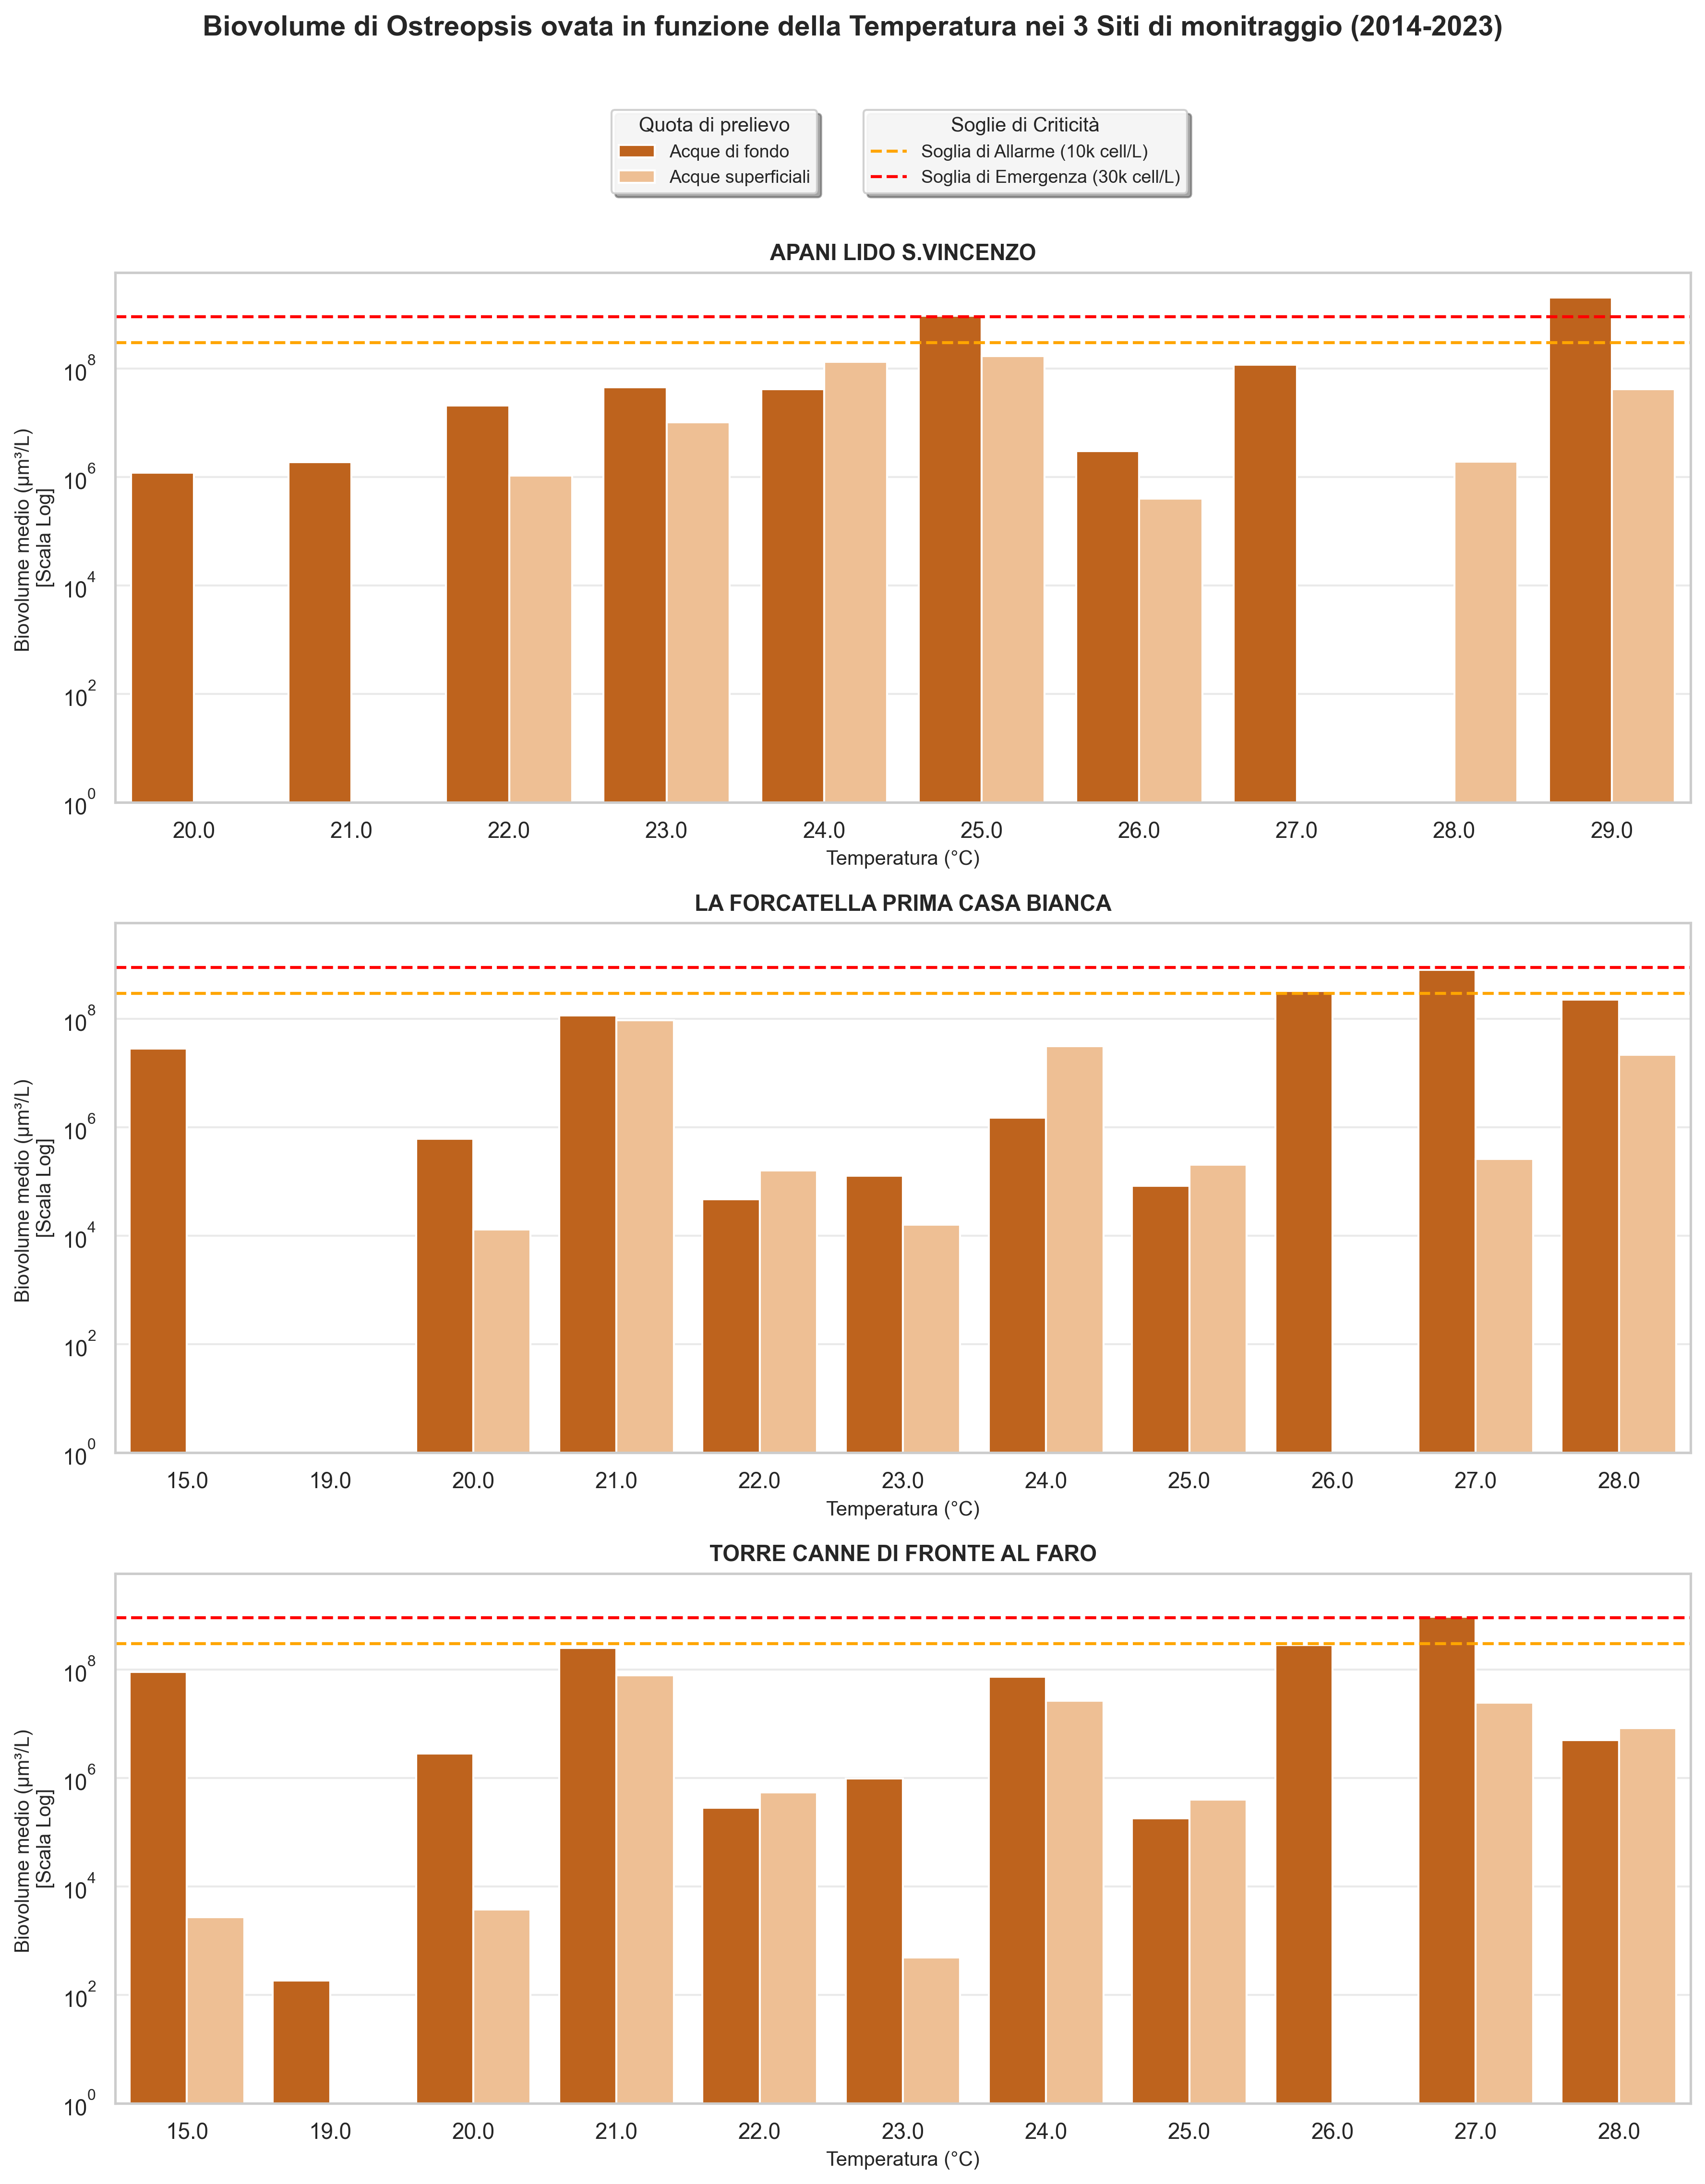

In [21]:
# Conversioni numeriche e gestione valori non validi
df['Temperatura (°C)'] = pd.to_numeric(df['Temperatura (°C)'], errors='coerce')
df['Biovolume (µm3/L)'] = pd.to_numeric(df['Biovolume (µm3/L)'], errors='coerce')

# Aggiungiamo +1 al biovolume per la scala logaritmica
df['Biovolume (µm3/L)'] = df['Biovolume (µm3/L)'].fillna(0) + 1

# Arrotondiamo la temperatura all'intero più vicino (°C) per creare classi omogenee nell'istogramma
df['Temp_Class'] = df['Temperatura (°C)'].round()

# Lista dei siti di monitoraggio
siti = ['APANI LIDO S.VINCENZO (BR)', 'LA FORCATELLA PRIMA CASA BIANCA (BR)', 'TORRE CANNE DI FRONTE AL FARO (BR)']

palette = {
        'FONDO': '#D95F02',
        'SUPERFICIE': '#FDBE85'
        }
# realizzazione dell'istogramma del biovolume in funzione della temperatura per ciascun sito
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 15), dpi=300, sharey=True)
assi = [ax1, ax2, ax3]
#max_biov definise il valore max per evitare sovrapoosizione dell'immagine con l'asse y 
max_biov = df['Biovolume (µm3/L)'].max()

for i, sito in enumerate(siti):
    ax = assi[i]
    
    # Filtraggio dati per la stazione corrente
    df_sito = df[df['SITO'].str.contains(sito, na=False, regex=False)].dropna(subset=['Temp_Class'])
    df_sito = df_sito.sort_values('Temp_Class') # Ordina i dati per classe di temperatura
    #sns,barplot crea un istogramma con barre affiancate per le due quote di campionamento (FONDO e COLONNA) per ciascuna classe di temperatura
    sns.barplot(
        data=df_sito, #data seleziona il df da cui prendere dati
        x='Temp_Class', #asse x = classi di temperatura arrotondate all'intero più vicino
        y='Biovolume (µm3/L)', #asse y = biovolume calcolato in precedenza
        hue='Quota prelievo', #colore delle barre in base alla quota di campionamento (FONDO o COLONNA)
        hue_order=['FONDO', 'SUPERFICIE'],
        palette=palette,
        errorbar=None,       # Disattiva le barre di errore se si desidera la media semplice
        estimator=np.mean,   # Media del biovolume per ciascuna classe di temperatura
        ax=ax,
        dodge=True          # Affianca le barre di Fondo e Colonna per la stessa temperatura
    )

    ax.axhline(y=soglia_allarme, color='orange', linestyle='--', linewidth=1.5, label='Soglia Allarme (10k cell/L)')
    ax.axhline(y=soglia_critica, color='red', linestyle='--', linewidth=1.5, label='Soglia Allarme (30k cell/L)')
    ax.set_yscale('log')
    ax.set_ylim(bottom=1)

    # Formattazione griglia e tick dell'asse Y
    ax.yaxis.set_major_locator(mticker.LogLocator(base=10.0))
    ax.yaxis.set_minor_locator(mticker.LogLocator(subs=range(2, 10)))
    ax.tick_params(axis='y', which='minor', length=3.5, width=0.5)
    ax.tick_params(axis='y', which='major', length=6, width=0.8)
    
    # Griglia orizzontale
    ax.grid(True, which='major', linestyle='-', alpha=0.4, axis='y')
    ax.grid(True, which='minor', linestyle=':', alpha=0.2, axis='y')

    # Titoli ed etichette
    nome = sito.split(' (')[0]
    ax.set_title(f'{nome}', fontsize=11, fontweight='bold', pad=6)
    ax.set_ylabel('Biovolume medio (μm³/L) \n[Scala Log]', fontsize=10)
    ax.set_xlabel('Temperatura (°C)', fontsize=10)
    ax.legend(title='Quota', title_fontsize=9, fontsize=8, loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
    
#rimuoviamo la leggenda dei singoli sottografici per fare una unica condivisa 
    if ax.get_legend() is not None:
        ax.get_legend().remove()

handles, labels = assi[0].get_legend_handles_labels()
handles_quota= handles[:2]
handles_soglia=handles[-2:]
fig.legend(handles_quota, ['Acque di fondo', 'Acque superficiali'], title='Quota di prelievo', loc='upper center', bbox_to_anchor=(0.42, 0.970), ncol=1, fontsize=9, title_fontsize=10, frameon=True, facecolor='white', framealpha=0.9, shadow=True, fancybox=True)
fig.legend(handles_soglia, ['Soglia di Allarme (10k cell/L)', 'Soglia di Emergenza (30k cell/L)'], title='Soglie di Criticità', loc='upper center', bbox_to_anchor=(0.60, 0.970), ncol=1, fontsize=9, title_fontsize=10, frameon=True, facecolor='white', framealpha=0.9, shadow=True, fancybox=True)

# Titolo generale
plt.suptitle(
    'Biovolume di Ostreopsis ovata in funzione della Temperatura nei 3 Siti di monitraggio (2014-2023)', 
    fontsize=14, 
    fontweight='bold', 
    y=1.01
)

plt.tight_layout(rect=[0, 0,1, 0.94])  #rect=[left, bottom, right, top] definisce l'area del grafico all'interno della figura (lasciando spazio per titolo e legenda)
plt.show()

### Osservazioni 
alga prolifera tra i 20°-28°C 

15°C picco non attribuibile solo alla temperatura (forse inizia a trovare le condizioni favorevoli?)


## Clorofilla


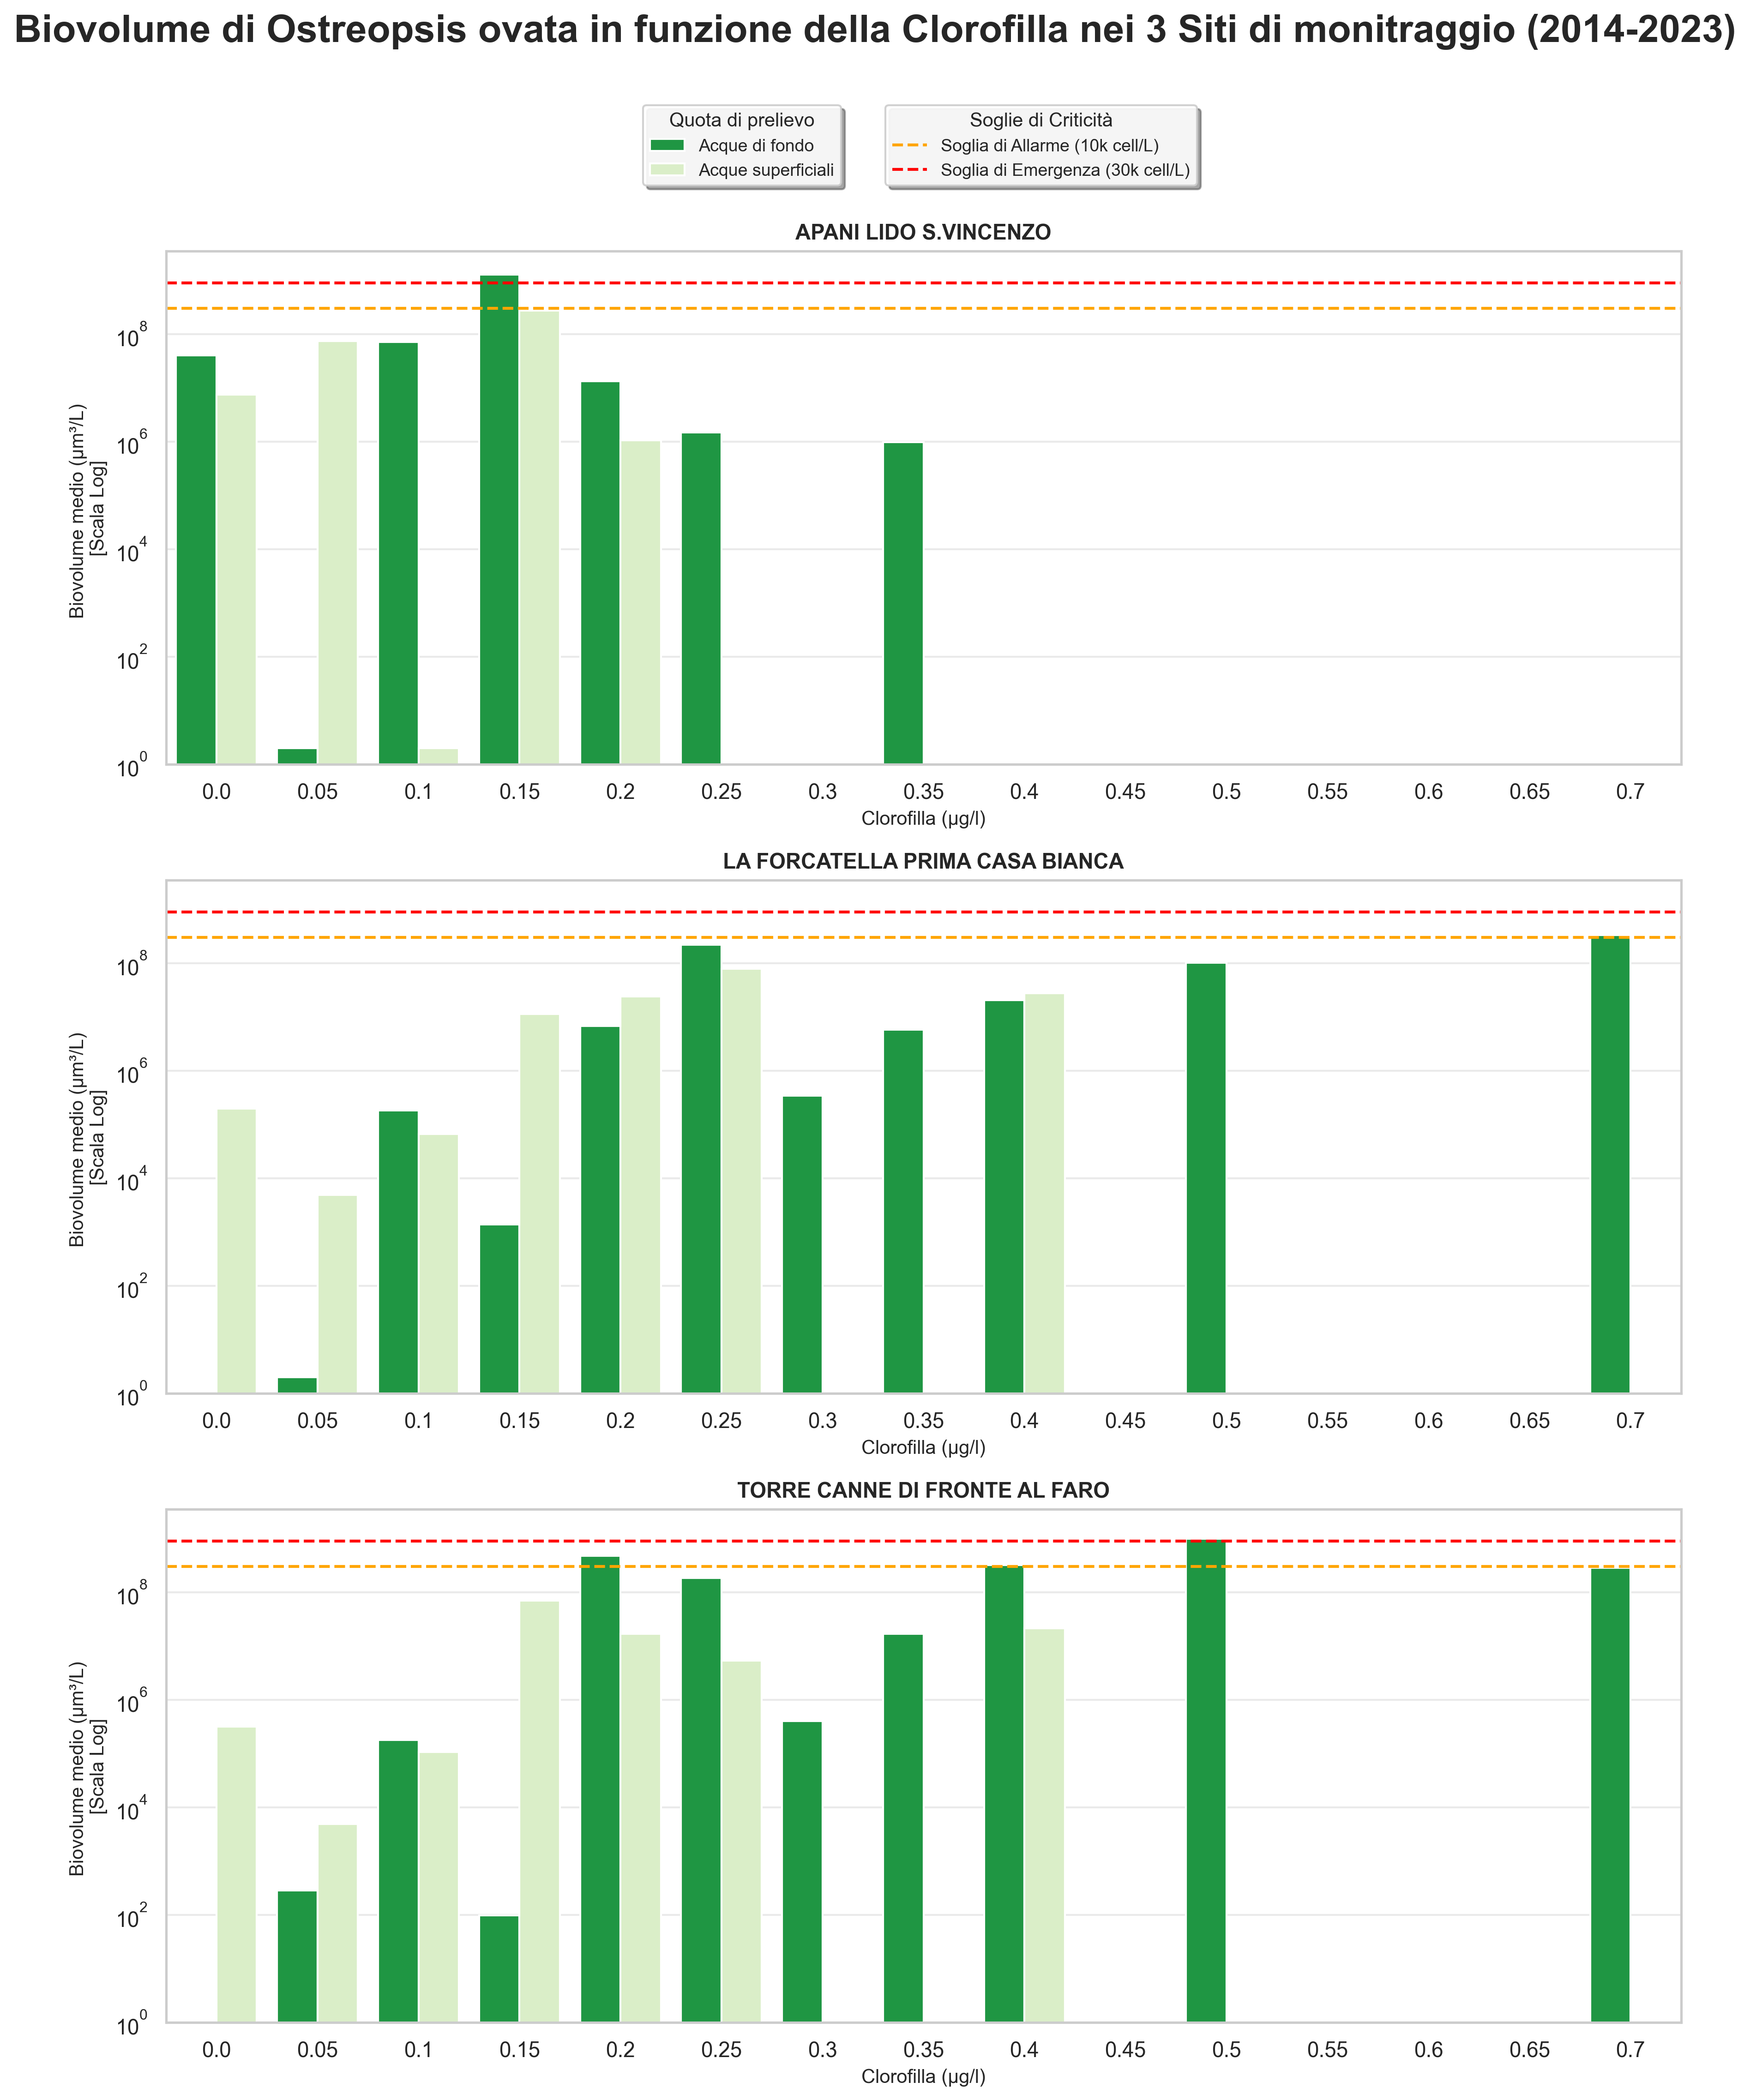

In [22]:
# Conversioni numeriche e gestione valori non validi
df['Clorofilla (µg/l)'] = pd.to_numeric(df['Clorofilla (µg/l)'], errors='coerce')
df['Biovolume (µm3/L)'] = pd.to_numeric(df['Biovolume (µm3/L)'], errors='coerce')
# Aggiungiamo +1 al biovolume per la scala logaritmica
df['Biovolume (µm3/L)'] = df['Biovolume (µm3/L)']+ 1

# Arrotondiamo la clorofilla all'intero più vicino (µg/l) per creare classi omogenee nell'istogramma
df['Clorofilla (µg/l)'] = pd.cut(df['Clorofilla (µg/l)'], bins=np.arange(0, 0.80, 0.05))
# Calcoliamo il valore centrale di ogni classe in modo da mostrarlo sull'assex 
df['Clorofilla (µg/l)'] = df['Clorofilla (µg/l)'].apply(lambda intervallo: intervallo.left if pd.notna(intervallo) else np.nan)
                                    # intervallo.left restituisce il valore sinistro dell'intervallo 
                                    # if pd.notna(intervallo) = se l'intervallo non è NaN, allora apply() intervallo.left
                                    # else np.nan = se l'intervallo è NaN, allora apply() restituisce NaN

# Lista dei siti di monitoraggio
siti = ['APANI LIDO S.VINCENZO (BR)', 'LA FORCATELLA PRIMA CASA BIANCA (BR)', 'TORRE CANNE DI FRONTE AL FARO (BR)']

palette = {'FONDO': "#0BAA3B", 'SUPERFICIE': "#DAF4C2"}

# realizzazione dell'istogramma 
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 15), dpi=300, sharey=True)
assi = [ax1, ax2, ax3]
#max_biov definise il valore max per evitare sovrapoosizione dell'immagine con l'asse y 
max_biov = df['Biovolume (µm3/L)'].max()

for i, sito in enumerate(siti):
    ax = assi[i]
    # Filtraggio dati per la stazione corrente
    df_filtered= df[df['SITO'].str.contains(sito, na=False, regex=False)].copy()
    df_filtered = df_filtered.dropna(subset=['Clorofilla (µg/l)'])  # Rimuove i valori NaN
    df_filtered = df_filtered.sort_values('Clorofilla (µg/l)') # Ordina i dati  

    #sns,barplot crea un istogramma con barre affiancate per le due quote di campionamento (FONDO e COLONNA) per ciascuna classe di temperatura
    sns.barplot(
        data=df_filtered, #prendiamo i valori dal df originale filtrato per il sito corrente, ciò permette di lavorare ad ogni ciclo coi valori del df per il sito corrente
        x='Clorofilla (µg/l)', #asse x = classi di temperatura arrotondate all'intero più vicino
        y='Biovolume (µm3/L)', 
        hue='Quota prelievo',
        hue_order=['FONDO', 'SUPERFICIE'],
        palette=palette,
        errorbar=None,       # Disattiva le barre di errore se si desidera la media semplice
        estimator=np.mean,   # Media del biovolume per ciascuna classe di temperatura
        ax=ax,
        dodge=True          # Affianca le barre di Fondo e Colonna per la stessa temperatura
    )
    if ax.get_legend() is not None:
        ax.get_legend().remove()

    ax.axhline(y=soglia_allarme, color='orange', linestyle='--', linewidth=1.5, label='Soglia Allarme (10k cell/L)')
    ax.axhline(y=soglia_critica, color='red', linestyle='--', linewidth=1.5, label='Soglia Allarme (30k cell/L)')
    ax.set_yscale('log')
    ax.set_ylim(bottom=1)
    
    # Formattazione griglia e tick dell'asse Y
    ax.tick_params(axis='y', which='minor', length=3.5, width=0.5)
    ax.tick_params(axis='y', which='major', length=6, width=0.8)
    
    # Griglia orizzontale
    ax.grid(True, which='major', linestyle='-', alpha=0.4, axis='y')
    ax.grid(True, which='minor', linestyle=':', alpha=0.2, axis='y')
    
    # Titoli ed etichette
    nome = sito.split(' (')[0]
    ax.set_title(f'{nome}', fontsize=11, fontweight='bold', pad=6)
    ax.set_ylabel('Biovolume medio (μm³/L) \n[Scala Log]', fontsize=10)
    ax.set_xlabel('Clorofilla (µg/l)', fontsize=10)                                                                              #frameon=True mostra il riquadro  #facecolor = colore sfonfo    #framealpha= opacità sfondo  

# Titolo generale
plt.suptitle(
    'Biovolume di Ostreopsis ovata in funzione della Clorofilla nei 3 Siti di monitraggio (2014-2023)', 
    fontsize=20, 
    fontweight='bold', 
    y=1.01
)
handles, labels = assi[0].get_legend_handles_labels()
handles_quota= handles[:2]
handles_soglia=handles[-2:]
fig.legend(handles_quota, ['Acque di fondo', 'Acque superficiali'], title='Quota di prelievo', loc='upper center', bbox_to_anchor=(0.42, 0.970), ncol=1, fontsize=9, title_fontsize=10, frameon=True, facecolor='white', framealpha=0.9, shadow=True, fancybox=True)
fig.legend(handles_soglia, ['Soglia di Allarme (10k cell/L)', 'Soglia di Emergenza (30k cell/L)'], title='Soglie di Criticità', loc='upper center', bbox_to_anchor=(0.60, 0.970), ncol=1, fontsize=9, title_fontsize=10, frameon=True, facecolor='white', framealpha=0.9, shadow=True, fancybox=True)


#creiamo lo sppazio per il titolo e legenda 
plt.tight_layout(rect=[0, 0, 1, 0.95])  #rect=[left, bottom, right, top] definisce l'area del grafico all'interno della figura (lasciando spazio per titolo e legenda)
plt.show()


# Analisi concentrazione dei nutrienti 


Raggruppiamo le concentrazioni in classi di ampiezza diversa:

- **Azoto totale:** classi di ampiezza 20 µg/L; 
sull'asse x mostriamo il valore più frequente di ogni classe, arrotondato al multiplo di 5 più vicino.
- **Fosforo totale:** classi di ampiezza 5 µg/L; 
sull'asse x mostriamo l'intervallo, ad esempio `0-5`, `5-10`, `10-15`.

L'asse y rappresenta il **biovolume medio** dei campioni appartenenti a ciascuna classe.

Azoto totale (N) (µg/L): ampiezza classi=20 µg/L,
Le etichette sull'asse x rappresentano il valore modale di ciascuna classe


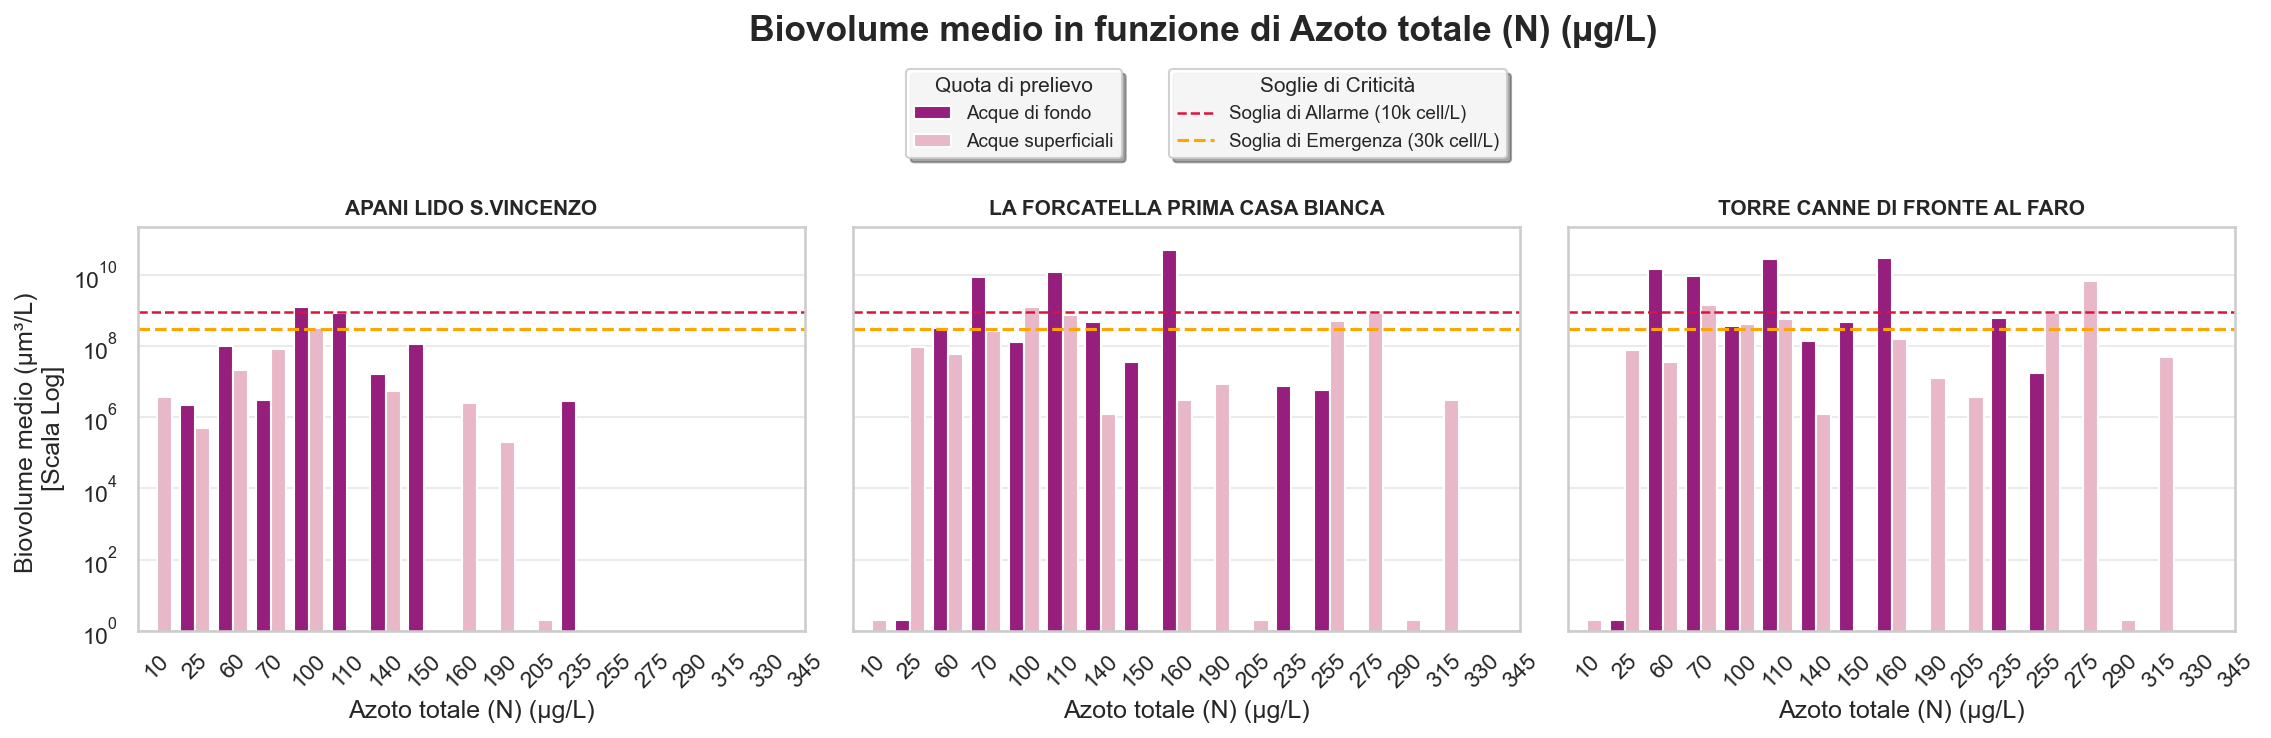

Fosforo totale (P) (µg/L): ampiezza classi=5 µg/L


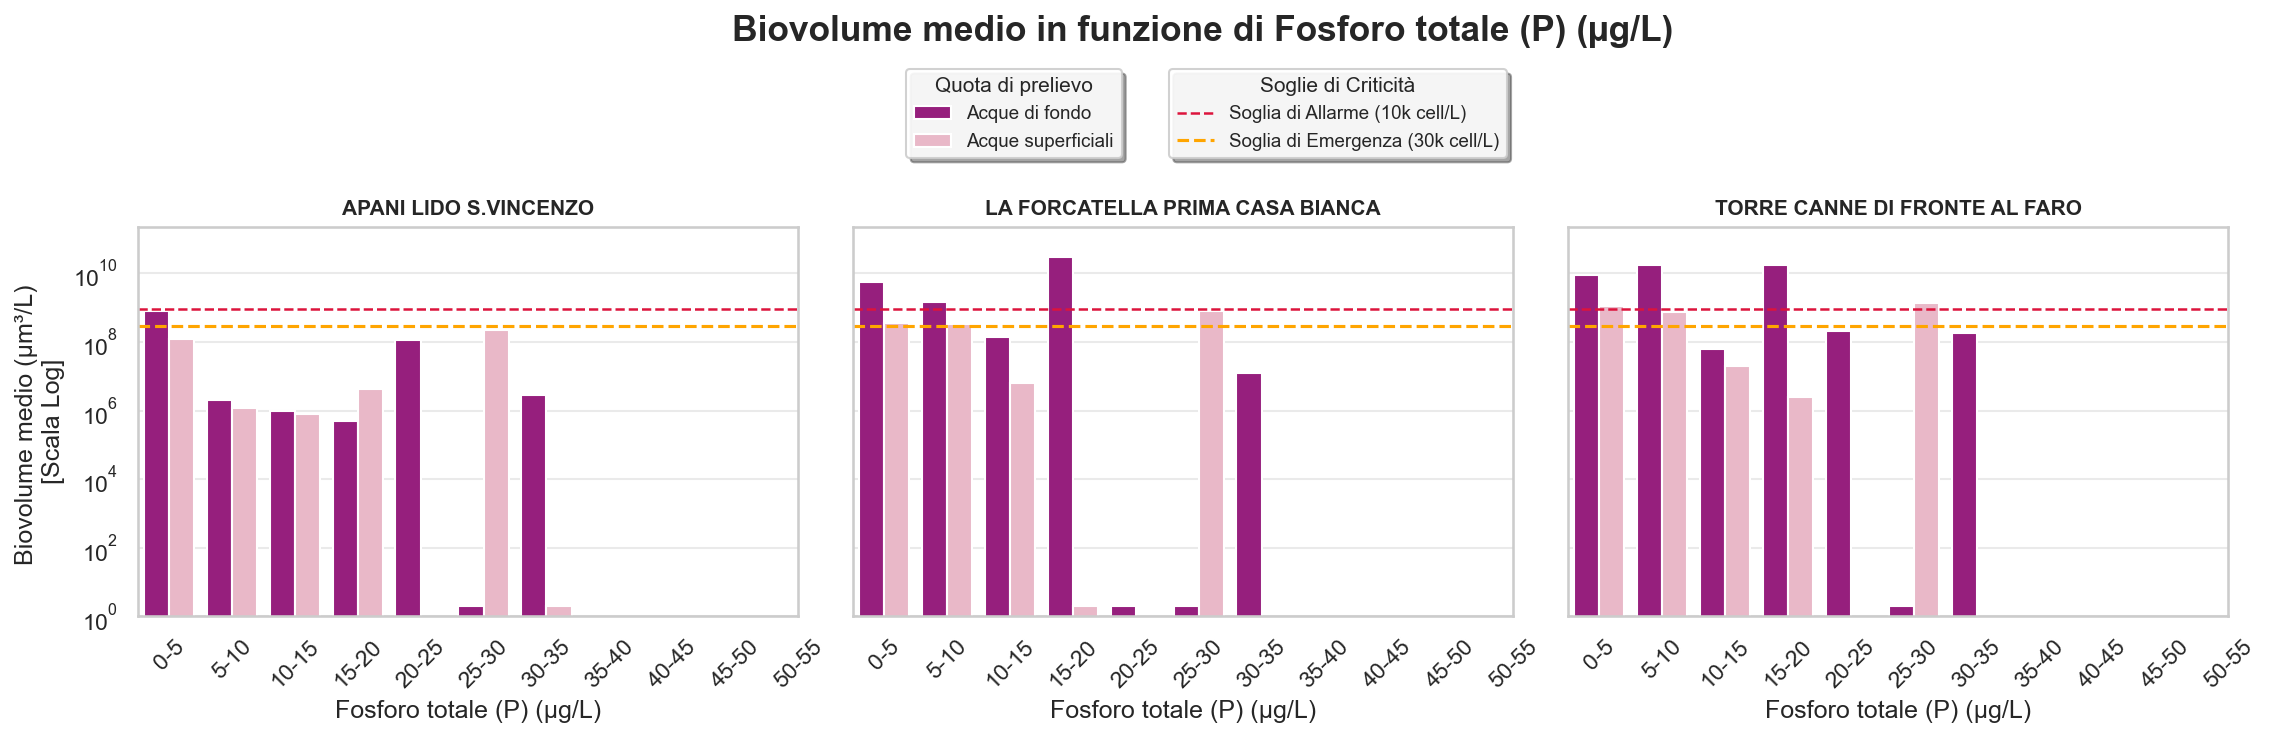

Numero di osservazioni utilizzate: 326


In [23]:
# PREPARAZIONE DEI DATI 
# creo un nuovo df contente solo le colonne di interesse x l'analisi dei nutrienti
df_nutrienti = df.copy() #prima copio il df originale
df_nutrienti['Biovolume (µm³/L)'] = df_nutrienti['Densità Ostreopsis ovata (cell/L)']*30000 +1  #creo una variabile contenente i valori del biovolume
# def il dizionario x associare alle colonne del df il valore da visualizzare sull'asse 
nutrienti = {
    'Azoto totale (N) (µg/l)': 'Azoto totale (N) (µg/L)',
    'Fosforo totale (P) (µg/l)': 'Fosforo totale (P) (µg/L)'
}
# controllo che le colonne dei nutrienti siano numeriche e converto eventuali valori non numerici in NaN
for colonna in nutrienti:
    #sostituisco i valori < 5 con 2.5 e i valori < 10 con 5, in modo da poterli considerare come valori numerici
    df_nutrienti[colonna]=df_nutrienti[colonna].replace({'<5':2.5, '<10':5}) 
    #converto in numero NaN le celle N.D.
    df_nutrienti[colonna] = pd.to_numeric(df_nutrienti[colonna], errors='coerce')
# rimuovo le righe con valori NaN nelle colonne di interesse    
         # (*nutrienti estrae automaticamentele i nomi delle colonne di Azoto e Fosforo nella lista )
df_nutrienti = df_nutrienti.dropna(subset=['SITO', 'Quota prelievo', 'Densità Ostreopsis ovata (cell/L)', *nutrienti]).copy()
# filtro il df per rimuovere eventuali valori negativi nelle colonne di interesse (dato che sono misure di concentrazione)
    #impongo le condizioni >0,  .all(axis=1) verifica che le condidizioni impostate siano vere contemporaneamente, se ciò accade resistuisce True
                                #axis=1 indica la direzione in cui controlla i valori (se =1 controlla riga px riga, se =0 scorre lungo le colonne)
df_nutrienti = df_nutrienti[(df_nutrienti['Densità Ostreopsis ovata (cell/L)'] >= 0) & (df_nutrienti[list(nutrienti)] >= 0).all(axis=1)].copy()

# SETUP GRAFICO:
siti= [
    'APANI LIDO S.VINCENZO (BR)',
    'LA FORCATELLA PRIMA CASA BIANCA (BR)',
    'TORRE CANNE DI FRONTE AL FARO (BR)'
]
 # definiamo l'ordine di visualizzazione della grafica tra fondo e superficie e i colori
ordine_quote = ['FONDO', 'SUPERFICIE']
palette = {'FONDO': "#AA0B88", 'SUPERFICIE': "#F1B0C5"}
# set_theme imposta lo stile dei grafici 
            # (style = 'whitegrid' = griglia bianca, 
            # context = 'notebook' = dimensione dei font e degli elementi grafici adatta per notebook)
sns.set_theme(style='whitegrid', context='notebook')

# SUDDIVISIONE DEI DATI IN CLASSI 
# Ciclo che esegue il codice sottostante per ciascun elemento del dizionario nutrienti (ovvero x azoto e fosforo)
# nutrienti.items() restituisce una lista di tuple (chiave, valore) 
    # colonna = nome della colonna del df 
    # etichetta = nome da visualizzare sull'asse x del grafico
for colonna, etichetta in nutrienti.items(): 
    # def l'ampiezza delle classi in base al nutriente (20 µg/L per l'azoto, 5 µg/L per il fosforo)
    ampiezza_classe = 20 if 'Azoto' in colonna else 5   
    # massimo definisce il valore massimo dell'asse x in base al valore massimo del nutriente e all'ampiezza delle classi
        # ceil() arrotonda all'intero superiore
    massimo = np.ceil(df_nutrienti[colonna].max() / ampiezza_classe) * ampiezza_classe
    # bordi definisce i bordi delle classi per l'istogramma, partendo da 0 fino al massimo, con passo pari all'ampiezza della classe
        #np.arange() crea un array di valori equidistanti tra 0 e il max+1 
    bordi = np.arange(0, massimo + 1, ampiezza_classe)
    #creiamo due nuove colonne nel df_nutrienti per associare ciascun valore del nutriente alla classe corrispondente e alla posizione della classe sull'asse x
    # mettendo la f prima delle virgolette si crea una f-string --> le quali permettono di inserire il valore di una variabile all'interno di una stringa, racchiudendo il nome della variabile tra graffe {}
    nome_classe = f'Classe_{colonna}' 
    nome_posizione = f'Posizione_{colonna}'
    #pd.cut() suddivide una serie di dati in intervalli 
        # df_nutrienti[colonna] = colonna di dati da raggruppare
        #bins= def.i bordi dei vari intervalli      #include_lowest = include il valore + basso 
   # il risultato è una nuova colonna (chiamata nome_classe) dove ogni riga ha il numero dell'intervallo a cui appartiene
    df_nutrienti[nome_classe] = pd.cut(df_nutrienti[colonna], bins=bordi, include_lowest=True)

    # dato che Matplotlib fatica a distanziare correttamente le barre tramite etichette di testo, associamo a ciascuna classe un numero progressivo (0,1,2,3,..) 
    classi = df_nutrienti[nome_classe].cat.categories
        # .cat.categories estrae l'elenco ordinato delle categorie create da pd.cut
        # il risultato viene salvato nella variabile classi = lista di tt gli intervalli possibili (es. [(0, 5], (5, 10], (10, 15)]) 
    # posizione = indice numerico progressivo associato a ciascuna classe 
    posizioni = list(range(len(classi))) 
        # len(classi) restituisce il numero di classi create da pd.cut
        # range() crea una seq di numeri interi che parte da 0 fino al n°tit di classi -1
        # list() converte questa seq in una lista 
    posizione_per_classe = dict(zip(classi, posizioni))
        # zip(classi, posizioni) prende gli elementi delle due liste e li accoppia a coppie e viene associato un numero all'intervallo 
        # dict() converte queste coppie in un dizionario = ovvero { (0, 5]: 0, (5, 10]: 1, (10, 15]: 2 }

    # crea una nuova colonna del df contenente le coordinate numeriche associate all'intervallo, che serve x posizionare gli intervalli sull'asse x in modo corrretto
    df_nutrienti[nome_posizione] = df_nutrienti[nome_classe].map(posizione_per_classe).astype(float)
        #.map() apploica la funz del dizionario: prende la colonna con le classi e sostituisce ciacun intervallo con il numero progressivo corrsipondnete 
        # .astype(float) converte i numeri interi in formato decimali (utile x evitare problemi di compatibilità con alcune funz del grafico)
    
    #calcolo del valore rappresentativo x ciascuna classe (quello che compare sull'etichetta dell'asse x)
        #groupby()[colonna] raggruppa le righe della tabella in base ai valori di una colonna (nome_classe)
        # [colonna] seleziona la colonna del nutriente da analizzare
        # agg() (abbreviazione di aggregate) applica una funzione (lamda) a ciascun gruppo
        #lamda valori: è una funzione anonima (rapida) che prende in input i valori di ciascun gruppo e restituisce il valore modale (mode) se esiste e ne prende il primo valoew utile della lista (.iloc[0]), altrimenti la media (mean) dei valori di quel gruppo 
    valore_rappresentativo = (df_nutrienti.groupby(nome_classe, observed=True)[colonna].agg(lambda valori: valori.mode().iloc[0] 
                                                                                            if not valori.mode().empty else valori.mean())
                              )
    
    if 'Azoto' in colonna:
        valori_x = [valore_rappresentativo.get(classe, classe.mid) for classe in classi]
        etichette_x = [str(int(np.floor(valore / 5 + 0.5) * 5)) for valore in valori_x ]
        etichette_uniche = []
        valori_usati = set()
        for etichetta_x in etichette_x:
            valore_x = int(etichetta_x)
            while valore_x in valori_usati:
                valore_x += 10
            valori_usati.add(valore_x)
            etichette_uniche.append(str(valore_x))
        etichette_x = etichette_uniche
    else:
        etichette_x = [
            f'{int(intervallo.left)}-{int(intervallo.right)}'
            for intervallo in classi
        ]

    if 'Azoto' in colonna:
        print(
            f'{etichetta}: ampiezza classi={ampiezza_classe} µg/L,\n'
                        "Le etichette sull'asse x rappresentano il valore modale di ciascuna classe"
        )
    else: 
        print(
            f'{etichetta}: ampiezza classi={ampiezza_classe} µg/L'
        )
    fig, assi = plt.subplots(
        1, 3, figsize=(18, 5), dpi=150, sharey=True
    )

    for ax, sito in zip(assi, siti):
        dati_sito = df_nutrienti[df_nutrienti['SITO'].eq(sito)]
        medie = (
            dati_sito
            .groupby([nome_posizione, 'Quota prelievo'], observed=True)
            ['Biovolume (µm3/L)']
            .mean()
            .round(0)
            .reset_index()
        )

        sns.barplot(
            data=medie,
            x=nome_posizione,
            y='Biovolume (µm3/L)',
            hue='Quota prelievo',
            hue_order=ordine_quote,
            palette=palette,
            estimator=np.mean,
            errorbar=None,
            ax=ax
        )
        ax.axhline(
            y=soglia_critica,
            color='crimson',
            linestyle='--',
            linewidth=1.2,
            label='Soglia di allarme'
        )
        
        ax.axhline(y=soglia_allarme, color='orange', linestyle='--', linewidth=1.5, label='Soglia Allarme (10k cell/L)')

        ax.set_yscale('log')
        ax.yaxis.set_major_locator(mticker.LogLocator(base=10.0))
        ax.yaxis.set_major_formatter(
            mticker.LogFormatterSciNotation(base=10, labelOnlyBase=True)
        )
        ax.set_title(sito.split(' (')[0], fontsize=10, fontweight='bold')
        ax.set_xlabel(etichetta)
        ax.set_ylabel('Biovolume medio (µm³/L) \n[Scala Log]')
        ax.set_ylim(bottom=1, top= max_biov * 1.1)
        ax.set_xticks(posizioni)
        ax.set_xticklabels(etichette_x, rotation=45)
        ax.grid(True, which='major', axis='y', alpha=0.4)
        ax.grid(True, which='minor', axis='y', linestyle=':', alpha=0.2)

        legenda = ax.get_legend()
        if legenda is not None:
            legenda.remove()

    handles, labels = assi[0].get_legend_handles_labels()
    handles_quota= handles[:2]
    handles_soglia=handles[-2:]
    fig.legend(handles_quota, ['Acque di fondo', 'Acque superficiali'], title='Quota di prelievo', loc='upper center', bbox_to_anchor=(0.38, 0.92), ncol=1, fontsize=9, title_fontsize=10, frameon=True, facecolor='white', framealpha=0.9, shadow=True, fancybox=True)
    fig.legend(handles_soglia, ['Soglia di Allarme (10k cell/L)', 'Soglia di Emergenza (30k cell/L)'], title='Soglie di Criticità', loc='upper center', bbox_to_anchor=(0.50, 0.92), ncol=1, fontsize=9, title_fontsize=10, frameon=True, facecolor='white', framealpha=0.9, shadow=True, fancybox=True)

    
    fig.suptitle(
        f'Biovolume medio in funzione di {etichetta}',
        x=0.45,
        y=0.98,
        ha='center',
        fontsize=17,
        fontweight='bold',
    )
    fig.tight_layout(rect=[0, 0, 0.85, 0.85]) 
    plt.show()

print(f'Numero di osservazioni utilizzate: {len(df_nutrienti)}')

### Osservazioni
Sembra bastino concentrazioni molto basse di nutrienti per favorire la proliferazione dell'alga

L'azoto è molto più abbondante del fosforo nelle acque lungo la costa pugliese


## Confronto tra azoto nitrico e ammoniacale

L'azoto totale è composto da forme diverse. Per visualizzarle senza perdere informazione, confrontiamo separatamente:

- **azoto nitrico** `N-NO3`;
- **azoto ammoniacale** `N-NH4`.

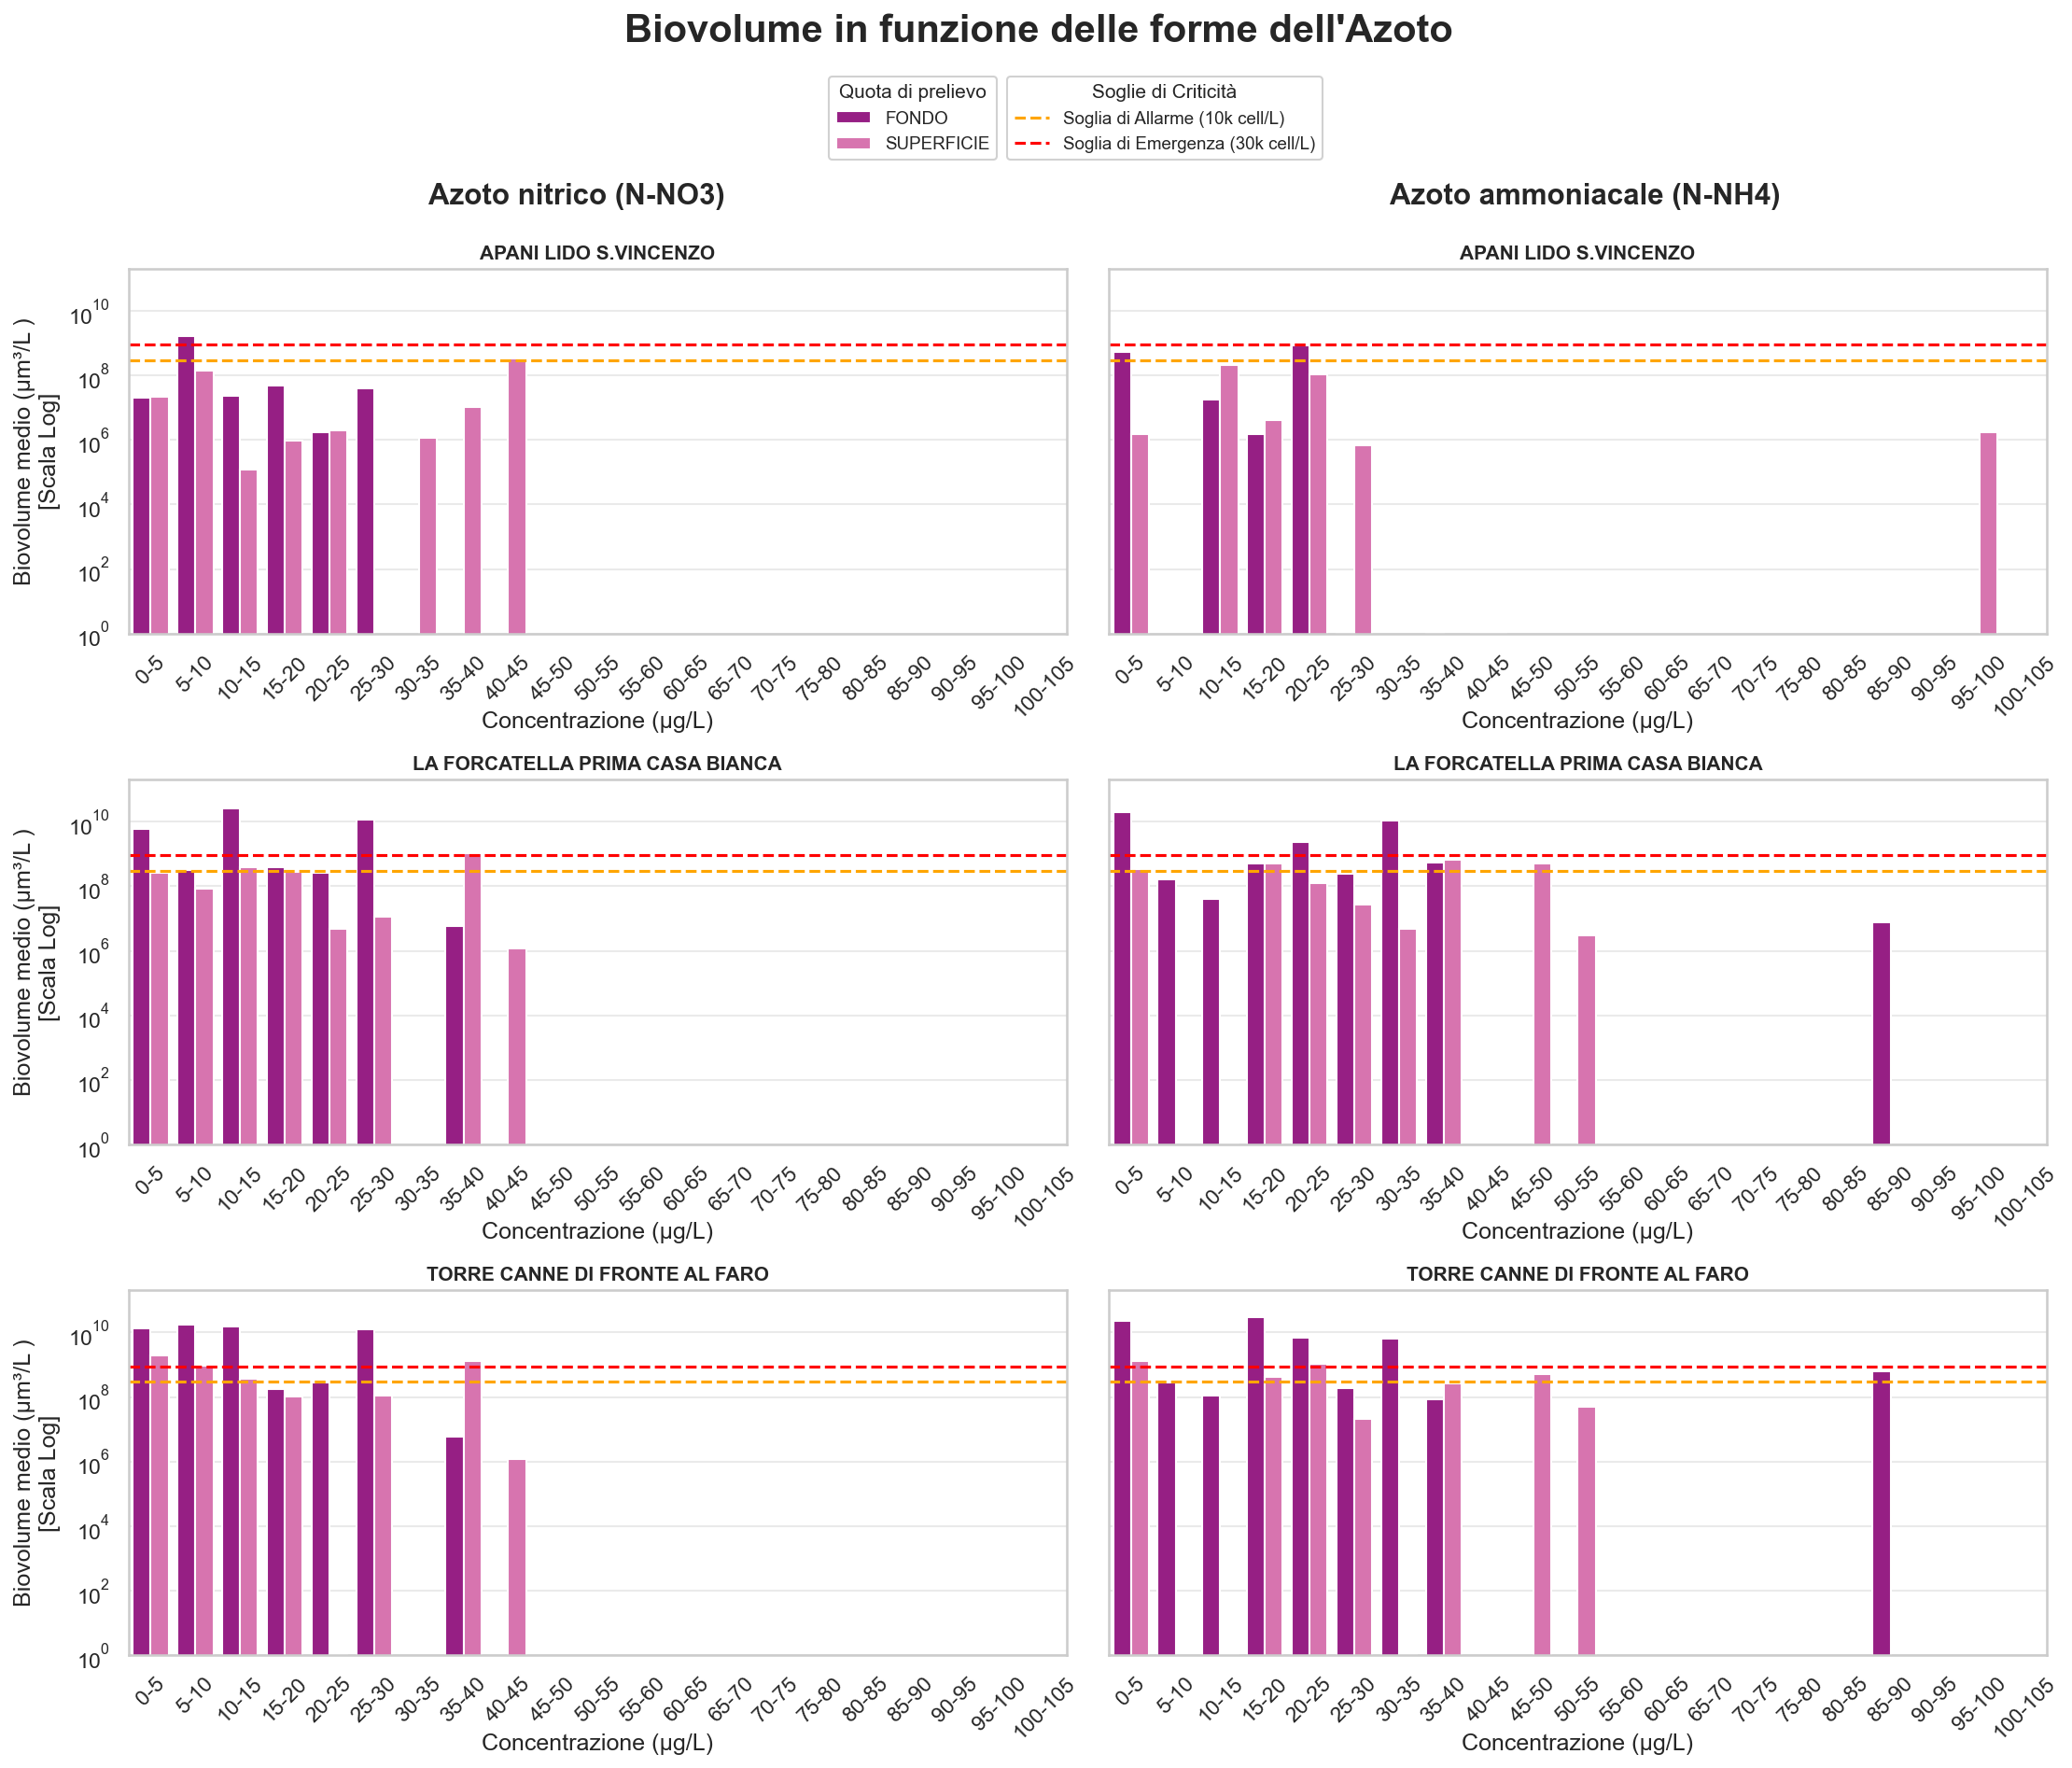

Numero di osservazioni complete utilizzate: 652


In [24]:
df_azoto = df.copy()
df_azoto['Densita_ostreopsis'] = pd.to_numeric(
    df_azoto['Densità Ostreopsis ovata (cell/L)'], errors='coerce'
)

BIOVOLUME_CELLULA = 30000
df_azoto['Biovolume_istogramma'] = (
    df_azoto['Densita_ostreopsis'] * BIOVOLUME_CELLULA + 1
)
# creiamo un dizionario per rinominare le colonne dell'azoto in modo più leggibile
colonne_azoto = {
    'Azoto nitrico (N-NO3) (µg/l)': 'Azoto nitrico (N-NO3)',
    'Azoto ammoniacale (N-NH4) (µg/l)': 'Azoto ammoniacale (N-NH4)'
}

for colonna in colonne_azoto:
    df_azoto[colonna] = pd.to_numeric(df_azoto[colonna], errors='coerce')

df_azoto = df_azoto.dropna(subset=['SITO', 'Quota prelievo', 'Densita_ostreopsis', *colonne_azoto]).copy()
df_azoto = df_azoto[(df_azoto['Densita_ostreopsis'] >= 0)& (df_azoto[list(colonne_azoto)] >= 0).all(axis=1)].copy()

ordine_siti = [
    'APANI LIDO S.VINCENZO (BR)',
    'LA FORCATELLA PRIMA CASA BIANCA (BR)',
    'TORRE CANNE DI FRONTE AL FARO (BR)'
]
ordine_forme = list(colonne_azoto.values())
ordine_quote = ['FONDO', 'SUPERFICIE']
palette = {'FONDO': "#AA0B92", 'SUPERFICIE': "#E863B2"}

df_azoto = df_azoto.melt(
    id_vars=['SITO', 'Quota prelievo', 'Biovolume_istogramma'],
    value_vars=list(colonne_azoto),
    var_name='Forma azoto',
    value_name='Concentrazione (µg/L)'
)
df_azoto['Forma azoto'] = df_azoto['Forma azoto'].map(colonne_azoto)
df_azoto['SITO'] = pd.Categorical(
    df_azoto['SITO'], categories=ordine_siti, ordered=True
)
df_azoto['Forma azoto'] = pd.Categorical(
    df_azoto['Forma azoto'], categories=ordine_forme, ordered=True
)

df_azoto['Classe'] = pd.cut(
    df_azoto['Concentrazione (µg/L)'],
    bins=np.arange(0, df_azoto['Concentrazione (µg/L)'].max() + 6, 5),
    include_lowest=True
)
df_azoto['Intervallo'] = df_azoto['Classe'].apply(
    lambda intervallo: (
        f'{int(intervallo.left)}-{int(intervallo.right)}'
        if pd.notna(intervallo) else np.nan
    )
)

intervalli = [
    f'{int(intervallo.left)}-{int(intervallo.right)}'
    for intervallo in df_azoto['Classe'].cat.categories
]
df_azoto['Intervallo'] = pd.Categorical(
    df_azoto['Intervallo'], categories=intervalli, ordered=True
)

sns.set_theme(style='whitegrid', context='notebook')
fig, assi = plt.subplots(3, 2, figsize=(15, 13), dpi=150, sharey=True)


# ciclo per creare i sottografici per ciascun sito e ciascuna forma di azoto
    #enumerate() restituisce una coppia (indice, valore) per ciascun elemento della lista
        #scorre la lista dei siti e associa un numero (indice) a ciascun sito, che viene usato per posizionare il sottografico nella griglia (dato che x ogni forma abbiamo 3 stazioni, la griglia è 3x2)
for riga, sito in enumerate(ordine_siti):
        # ciclo che scorre le forme di azoto associando un indice a ciascuna forma
    for colonna, forma in enumerate(ordine_forme):
        # crea il sottografico incrociando le coordinate della matrice (es sito1, forma0 riga1, colonna0 --> riquadro centrale a sx)
        ax = assi[riga, colonna]
        # filtrare i dati per il sito e la forma di azoto di quel ciclo
        dati = df_azoto[
            (df_azoto['SITO'] == sito)
            & (df_azoto['Forma azoto'] == forma)
        ]
        # calcolo delle medie del biovolume per ciascun intervallo di concentrazione e quota di prelievo
            #raggruppa i dati x intervallo di conc e quota prelievo
             #obs=True evita di creare grp vuoti x combinazione non presente nei dati
             #Calcola la media del biov x ciascun gruppo          #.round(0) = arrotonda all'intero + vicino    
                                                                  # .reset_index() trasforma le serie raggruppate in normali colonne del df in moo da poter poi usare la funzione di Seaborn sns.barplot() 
        medie = (dati.groupby(['Intervallo', 'Quota prelievo'], observed=True)['Biovolume_istogramma'] .mean().round(0).reset_index())
        
        #creazione istogramma 
        sns.barplot(
            data=medie, 
            x='Intervallo',
            y='Biovolume_istogramma',
            hue='Quota prelievo',
            hue_order=ordine_quote,
            palette=palette,
            estimator=np.mean,
            errorbar=None,
            ax=ax
        )
        #disegno linee di soglia di criticità
        ax.axhline(
            y=soglia_allarme,
            color='orange',
            linestyle='--',
            linewidth=1.5,
            label='Soglia di Allarme (10k cell/L)'
        )
        ax.axhline(
            y=soglia_critica,
            color='red',
            linestyle='--',
            linewidth=1.5,
            label='Soglia di Emergenza (30k cell/L)'
        )
        ax.set_yscale('log')
        ax.set_ylim(bottom=1, top=max_biov *1.0)
                #mticker.LogLocator(base=10.0) = imposta la scala logaritmica con base 10  
        ax.yaxis.set_major_locator(mticker.LogLocator(base=10.0))
                # mticker.LogFormatterSciNotation(base=10, labelOnlyBase=True) = formatta i tick dell'asse y in notazione scientifica, mostrando solo le potenze di 10
        ax.yaxis.set_major_formatter(
            mticker.LogFormatterSciNotation(base=10, labelOnlyBase=True)
        )
        ax.set_title(sito.split(' (')[0], fontsize=10, fontweight='bold', pad=5) #pad = distanza tra titolo e grafico
        ax.set_xlabel('Concentrazione (µg/L)', labelpad=-5) #labelpad = distanza tra etichetta e asse x
        ax.set_ylabel('Biovolume medio (µm³/L )\n[Scala Log]')
        ax.tick_params(axis='x', rotation=45)
        ax.grid(True, which='major', axis='y', alpha=0.4)
        ax.grid(True, which='minor', axis='y', linestyle=':', alpha=0.2)

        legenda = ax.get_legend()
        if legenda is not None:
            legenda.remove()

# tiitoli dei sottografici 
    #fig.text(x,y, titolo...) 
fig.text( 
    0.28, 0.87, 'Azoto nitrico (N-NO3)',
    ha='center', va='center', fontsize=15, fontweight='bold'
)    #ha= horizontal alignment
     #va= vertical alignment
fig.text(
    0.76, 0.87, 'Azoto ammoniacale (N-NH4)',
    ha='center', va='center', fontsize=15, fontweight='bold'
)
        #handles = oggetti legenda
        #labels =etichette legenda 
        # assi[0, 0] = primo sottografico (riga 0, colonna 0)  
# .get_legend_handles_labels() = restituisce due liste: la prima contiene gli oggetti della legenda (handles), la seconda le etichette corrispondenti (labels)
handles, labels = assi[0, 0].get_legend_handles_labels()
fig.legend(
    handles[:2],
    ['FONDO', 'SUPERFICIE'],
    title='Quota di prelievo',
    loc='upper center',
    bbox_to_anchor=(0.44, 0.94),
    ncol=1,
    fontsize=9,
    title_fontsize=10,
    frameon=True,
    facecolor='white',
    framealpha=0.9
)
fig.legend(
    handles[2:4], #handles[2:4] seleziona le ultime due voci della legenda, che corrispondono alle soglie di criticità
    ['Soglia di Allarme (10k cell/L)',
     'Soglia di Emergenza (30k cell/L)'],
    title='Soglie di Criticità',
    loc='upper center',
    bbox_to_anchor=(0.56, 0.94),
    ncol=1,   #n°colonne legenda 
    fontsize=9,
    title_fontsize=10,
    frameon=True,
    facecolor='white',
    framealpha=0.9
)
fig.suptitle(
    'Biovolume in funzione delle forme dell\'Azoto',
    fontsize=20,
    fontweight='bold',
    y=0.97
)
#rect=[sx, bottom, dx, top] --> definisce l'area entro cui i grafici devono essere disegnati, lasciando spazio per titolo e legenda
fig.tight_layout(rect=[0, 0, 1, 0.89], h_pad=1.0)   #h_pad= distanza verticale tra i sottografici
plt.show()

print(f'Numero di osservazioni complete utilizzate: {len(df_azoto)}')

###  Osservazioni
La concentrazione dell'alga diventa rilevante non appena i nutrienti diventano disponibili, bastano anche pochi μg/L per farla proliferare

picco anomalo nelle stazioni intorno ai 90 μg/L di ammoniaca; 
causa?

In [25]:
# verifico l'intervallo in cui ricadono i valori 
df['Ossigeno disciolto (O2) (mg/l)'] = pd.to_numeric(df['Ossigeno disciolto (O2) (mg/l)'], errors='coerce')
df['pH (unità)'] = pd.to_numeric(df['pH (unità)'], errors='coerce')
df['Salinità (PSU)'] = pd.to_numeric(df['Salinità (PSU)'], errors='coerce')

min_OD = df['Ossigeno disciolto (O2) (mg/l)'].min()
max_OD = df['Ossigeno disciolto (O2) (mg/l)'].max()
print(f'Valori minimi e massimi di Ossigeno disciolto: {min_OD:.2f} - {max_OD:.2f} mg/L')
min_pH = df['pH (unità)'].min()
max_pH = df['pH (unità)'].max()
print(f'Valori minimi e massimi di pH: {min_pH:.2f} - {max_pH:.2f} unità')
min_sal= df['Salinità (PSU)'].min()
max_sal= df['Salinità (PSU)'].max()
print(f'Valori minimi e massimi di Salinità: {min_sal:.2f} - {max_sal:.2f} PSU')


Valori minimi e massimi di Ossigeno disciolto: 5.56 - 8.50 mg/L
Valori minimi e massimi di pH: 7.46 - 8.51 unità
Valori minimi e massimi di Salinità: 36.22 - 39.26 PSU


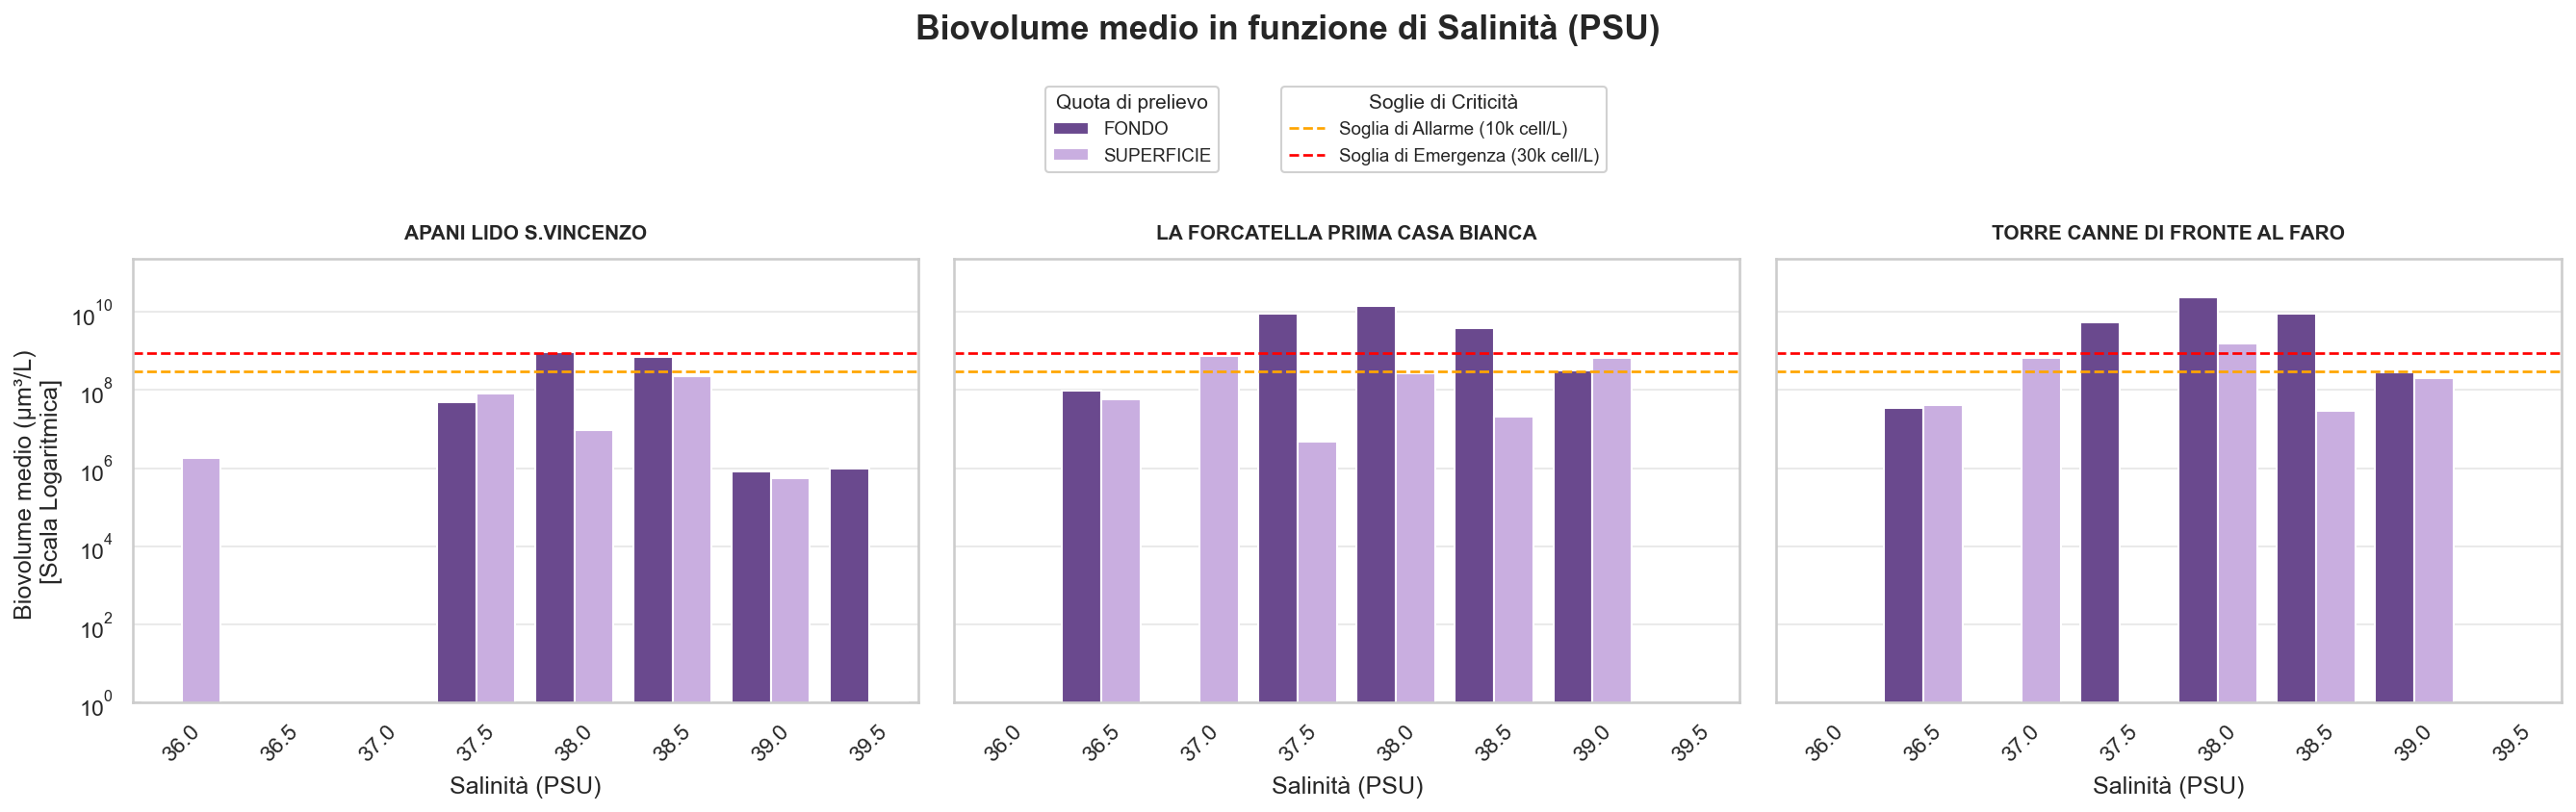

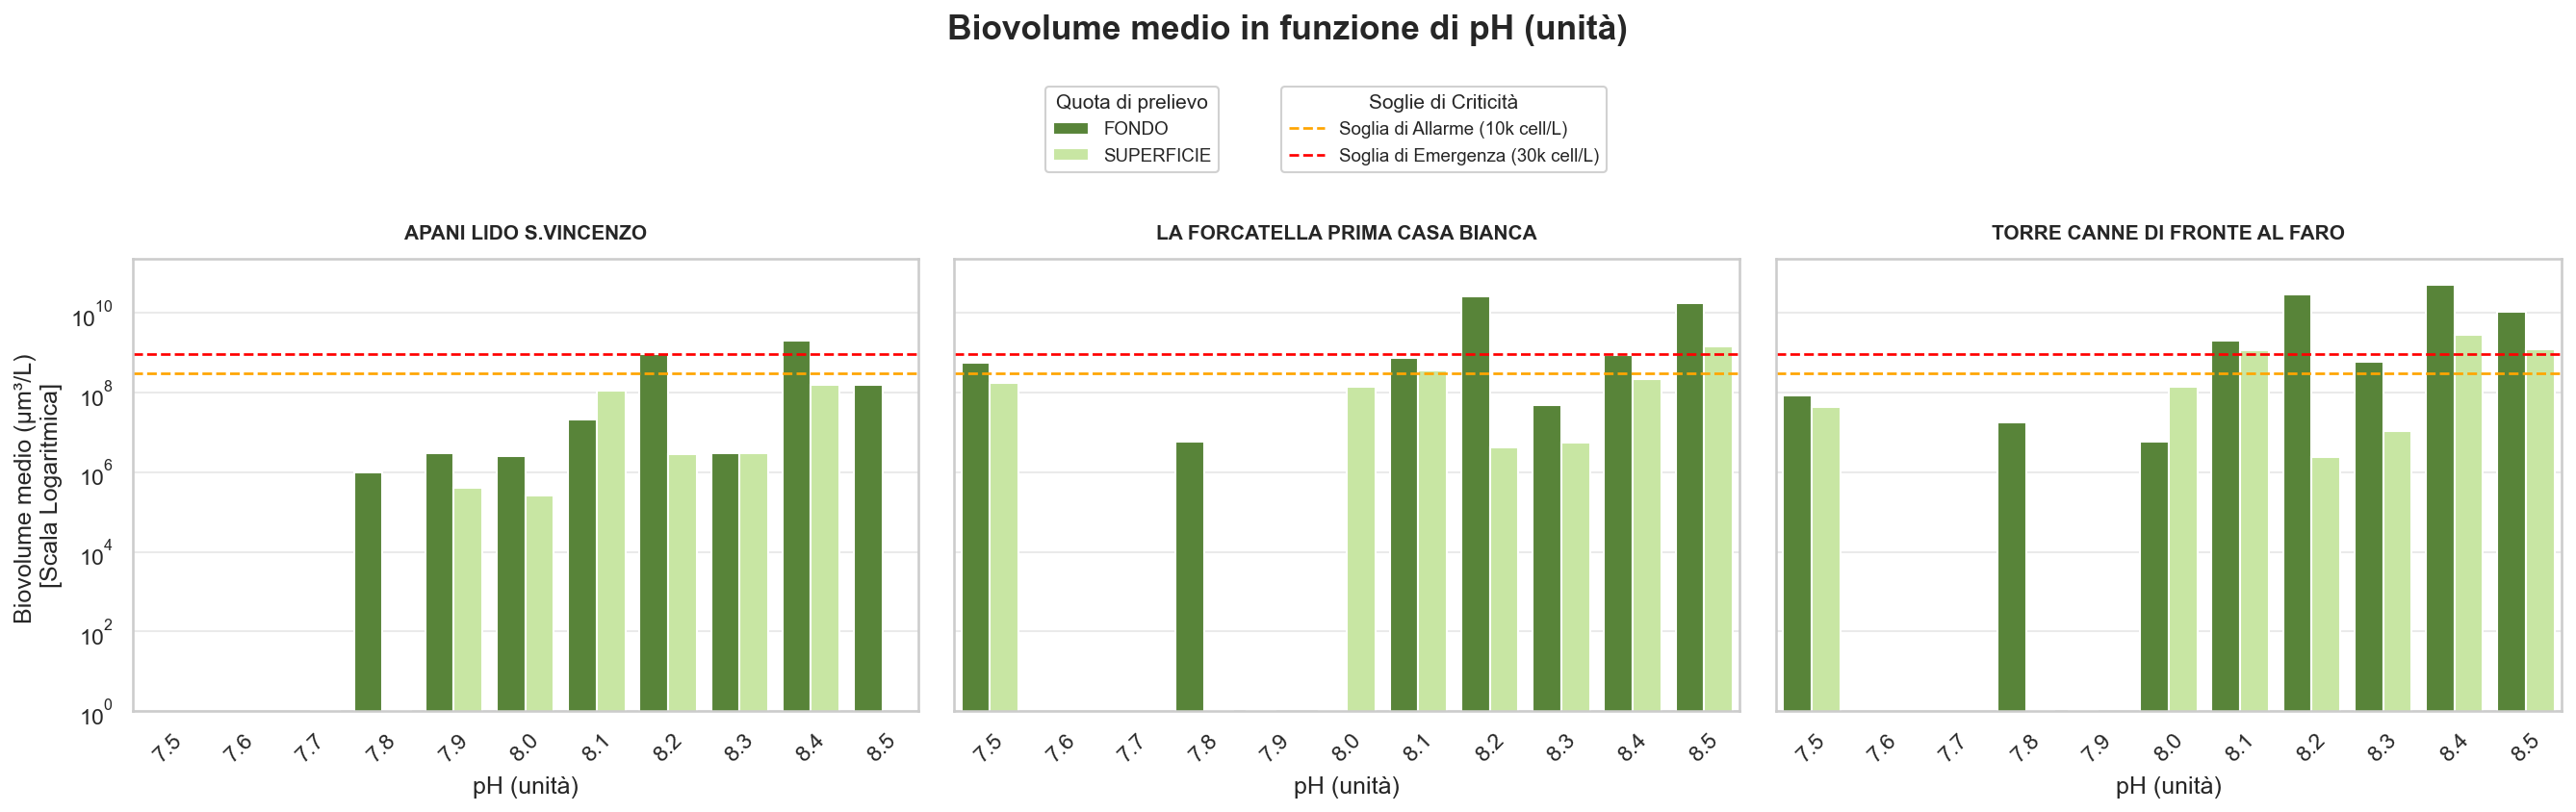

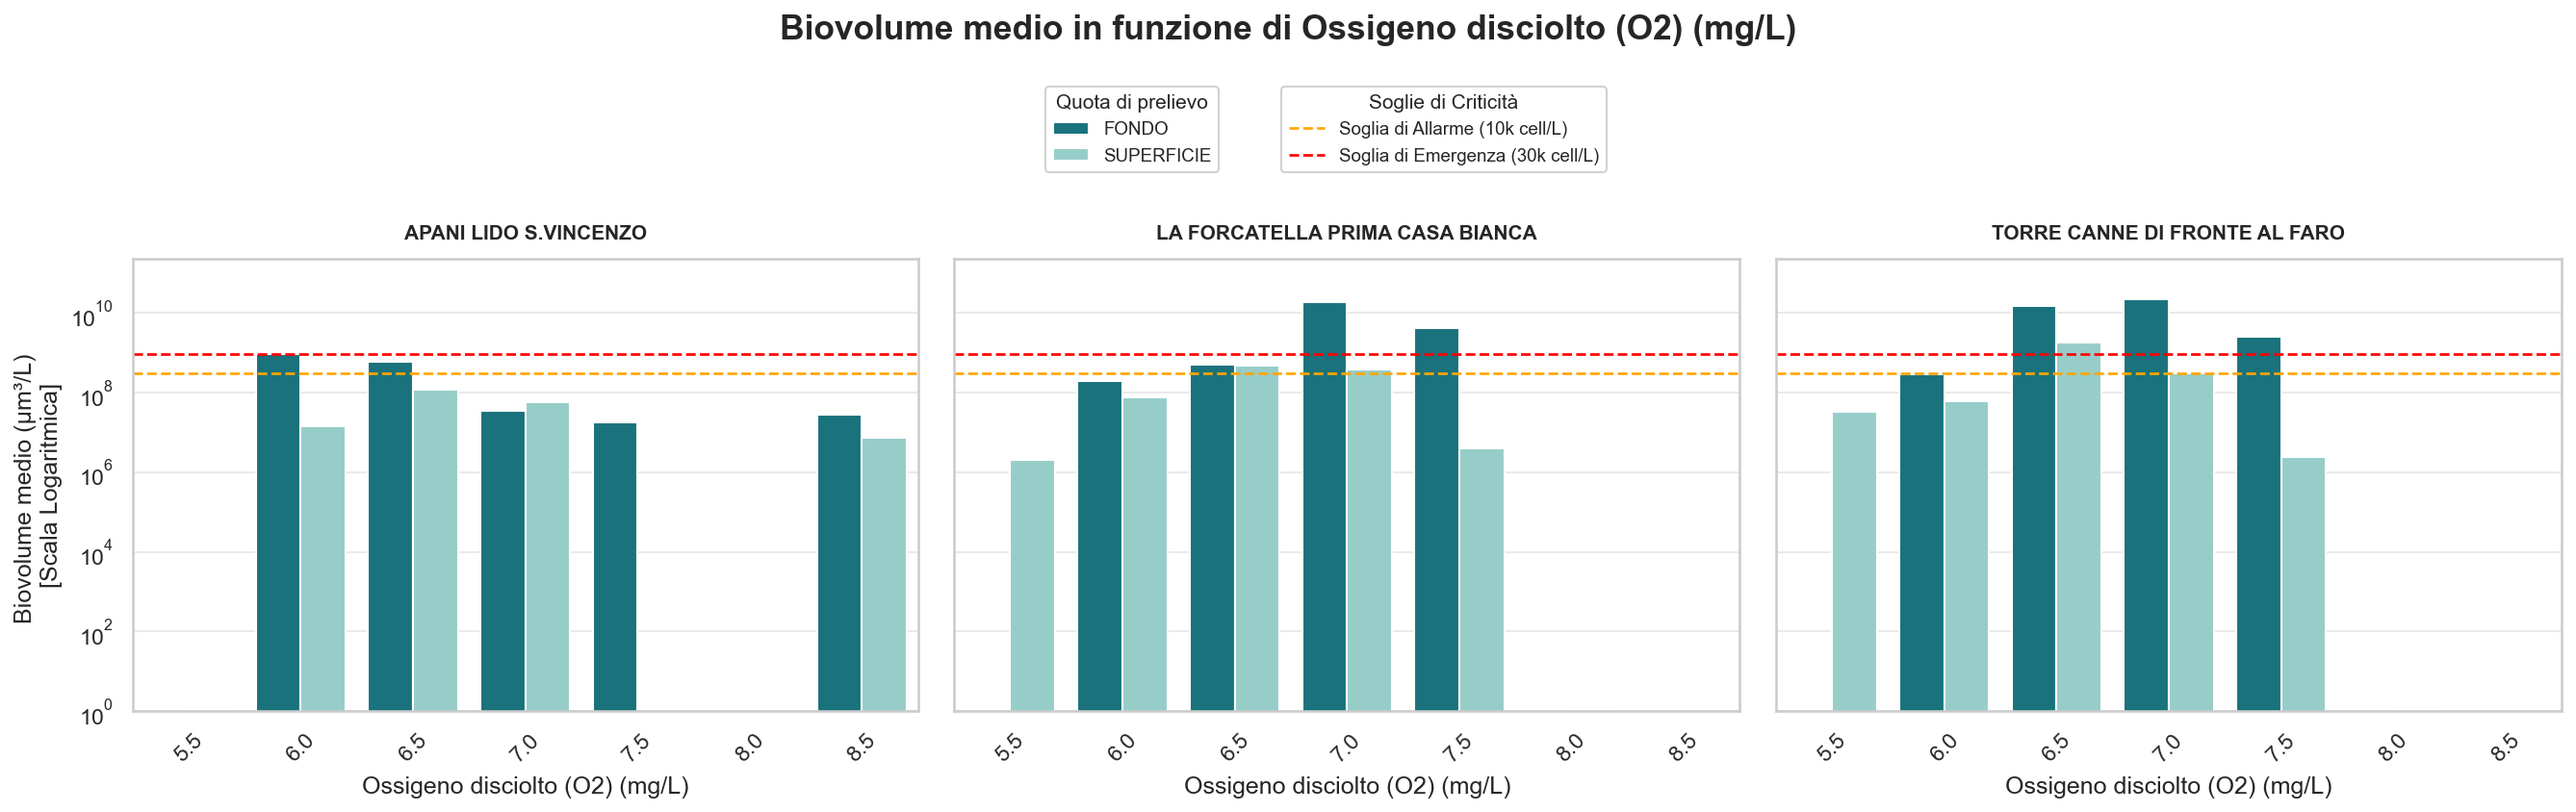

Numero di osservazioni utilizzate: 316


In [26]:
# Relazione tra biovolume e parametri chimico-fisici
# creo un dizionario per associare a ciascun parametro chimico-fisico il nome da visualizzare sull'asse x 
    # & il passo di arrotondamento dei valori (0.5 per salinità e ossigeno, 0.1 per pH dato che subisce variazioni ridotte)
parametri_fisici = {
    'Salinità (PSU)': ('Salinità (PSU)', 0.5),
    'pH (unità)': ('pH (unità)', 0.1),
    'Ossigeno disciolto (O2) (mg/l)': ('Ossigeno disciolto (O2) (mg/L)', 0.5)
}

palette_parametri = {
    'Salinità (PSU)': {
        'FONDO': '#6A3D9A',
        'SUPERFICIE': '#C9A6E8'
    },
    'pH (unità)': {
        'FONDO': "#56902D",
        'SUPERFICIE': "#C9F198"
    },
    'Ossigeno disciolto (O2) (mg/l)': {
        'FONDO': '#087F8C',
        'SUPERFICIE': '#8ED6D1'
    }
}
#creare una copia indipendente dal dataset originale evita che le modifiche alterino i dati in memoria
df= df.copy()
df['Densita_ostreopsis'] = pd.to_numeric( df['Densità Ostreopsis ovata (cell/L)'],errors='coerce')
df['Biovolume (µm³/L)'] = (df['Densita_ostreopsis'] * BIOVOLUME_CELLULA + 1)
#il ciclo converte in numerico le colonne dei parametri chimico-fisici, sostituendo eventuali valori non numerici con NaN
for colonna in parametri_fisici:
    df[colonna] = pd.to_numeric(df[colonna], errors='coerce')
#rimuove le righe con valori NaN nelle colonne di interesse 
df = df.dropna(subset=['SITO', 'Quota prelievo', 'Biovolume (µm³/L)', *parametri_fisici]).copy()
# verifica che i valori siano positivi         #.all(axis=1) assicura che la condizione sia vera x tt le colonne
df = df[(df['Densita_ostreopsis'] >= 0)& (df[list(parametri_fisici)] >= 0).all(axis=1)].copy()

# definisco l'ordine dei siti e delle quote di prelievo da visualizzare nei grafici
ordine_siti = [
    'APANI LIDO S.VINCENZO (BR)',
    'LA FORCATELLA PRIMA CASA BIANCA (BR)',
    'TORRE CANNE DI FRONTE AL FARO (BR)'
]
ordine_quote = ['FONDO', 'SUPERFICIE']

# scorro la lista dei parametri da analizzare e creo un associazione colonna-etichetta-passo 
    #colonna per indicare quale colonna del df analizzare, 
    # etichetta per indicare il nome del valore da visualizzare sull'asse x
    # passo per indicare l'intervallo di arrotondamento
for colonna, (etichetta, passo) in parametri_fisici.items():
    #creiamo una copia x lavorare sui dati senza modificare il df da cui prendiamo i valori
    dati_parametro = df.copy()
    if passo == 0.5:
        # aggiungiamo una colonna al df modificato x salvare i valori arrotondati 
        dati_parametro['Valore x'] = (dati_parametro[colonna] * 2).round() / 2
    else:
        dati_parametro['Valore x'] = dati_parametro[colonna].round(1)

    
    # Calcola minimo e massimo effettivi
    min_x = dati_parametro['Valore x'].min()
    max_x = dati_parametro['Valore x'].max()
    # Crea una sequenza continua con il passo corretto (0.1 per pH, 0.5 per gli altri)
        #np.arange( start, stop, step) = genera una seq di numeri a partire dal minimo aumentando ogni volta del valore indicato dal passo fino a raggiungere il max
        # max+passo/2 = aggiungiamo 1/2 passo al max x includerlo nell'intervallo altrimenti np.arange() si fermerebbe prima
    valori_x = np.arange(min_x, max_x + passo/2, passo).round(1)
    # sorted() ordina i valori in ordine crescente 
    # np.unique() elimina evebtuali duplicati (in modo da non scrivere lo stesso valore due volte sull'asse x) 
    valori_x = sorted(np.unique(valori_x))

    # formattazione delle etichette x l'asse x 
        # f'{valore:1f}' = converte il valore in stringa con 1 cifra decimale
    etichette_x = [f'{valore:.1f}' for valore in valori_x]
    #crea una nuova colonna che associa a ciscun valore del parametro un'etichetta 
        #pdCategorical(..., categories= etichette_x, ordered=True) = crea una colonna categoriale (sulla colonna 'Valore x), utile x ordinare i valori sull'asse x
            #categories= categorie ammesse 
        # map(dict(zip(valori_x, etichette_x))) utilizza il dizionario creato x sostituire ogni valore della colonna Valore x con la sua etichetta corrispondente
            # zip() = accoppia i valori di due liste in coppie (valore, etichetta)
            # dict() trasforma queste corrispondenze in un dizionario
    dati_parametro['Intervallo'] = pd.Categorical(dati_parametro['Valore x'].map(dict(zip(valori_x, etichette_x))),
        categories=etichette_x,ordered=True
                                                 )

    fig, assi = plt.subplots(1, 3, figsize=(18, 5.5), dpi=150, sharey=True)

    #ciclo che scorre contemporamentamente gli assi dei grafici e i siti di campionamento selezionando di volta in volta i dati relativi a un singolo sito
    for ax, sito in zip(assi, ordine_siti):
        #selezioniamo i dati relativi al sito corrente -->  dati_parametro[] = usa il risultato come filtro e restituisce solo le righe corrispondenti
            #dati_parametro['SITO'] = seleziona la colonna contente i nomi dei siti 
            # .eq(sito) = verifica quali righe hanno un valore di SITO uguale al sito corrent
        dati_sito = dati_parametro[dati_parametro['SITO'].eq(sito)]
        medie = (dati_sito.groupby(['Intervallo', 'Quota prelievo'], observed=True)['Biovolume (µm³/L)'].mean().round(0).reset_index())

        sns.barplot(
            data=medie,
            x='Intervallo', #
            y='Biovolume (µm³/L)',
            hue='Quota prelievo',
            hue_order=ordine_quote,
            palette=palette_parametri[colonna],
            estimator=np.mean,
            errorbar=None,
            ax=ax
        )

        ax.axhline(
            y=soglia_allarme,
            color='orange',
            linestyle='--',
            linewidth=1.3,
            label='Soglia di Allarme (10k cell/L)'
        )
        ax.axhline(
            y=soglia_critica,
            color='red',
            linestyle='--',
            linewidth=1.3,
            label='Soglia di Emergenza (30k cell/L)'
        )
        ax.set_yscale('log')
        ax.set_ylim(bottom=1, top= max_biov * 1.1)
        ax.set_title(sito.split(' (')[0], fontsize=10, fontweight='bold', pad=10)
        ax.set_xlabel(etichetta, labelpad=5)
        ax.set_ylabel('Biovolume medio (µm³/L) \n[Scala Logaritmica]' if ax is assi[0] else '')
        ax.tick_params(axis='x', rotation=45)
        ax.yaxis.set_major_locator(mticker.LogLocator(base=10.0))
        ax.yaxis.set_major_formatter(mticker.LogFormatterSciNotation(base=10, labelOnlyBase=True))
        ax.grid(True, which='major', axis='y', alpha=0.4)
        ax.grid(True, which='minor', axis='y', linestyle=':', alpha=0.2)

        legenda = ax.get_legend()
        if legenda is not None:
            legenda.remove()

    handles, labels = assi[0].get_legend_handles_labels()
    fig.legend(
        handles[:2],
        ['FONDO', 'SUPERFICIE'],
        title='Quota di prelievo',
        loc='upper center',
        bbox_to_anchor=(0.44, 0.94),
        ncol=1,
        fontsize=9,
        title_fontsize=10,
        frameon=True,
        facecolor='white',
        framealpha=0.9
    )
    fig.legend(
        handles[2:4],
        ['Soglia di Allarme (10k cell/L)',
         'Soglia di Emergenza (30k cell/L)'],
        title='Soglie di Criticità',
        loc='upper center',
        bbox_to_anchor=(0.56, 0.94),
        ncol=1, 
        fontsize=9,
        title_fontsize=10,
        frameon=True,
        facecolor='white',
        framealpha=0.9
    )
    fig.suptitle(
        f'Biovolume medio in funzione di {etichetta}',
        fontsize=17,
        fontweight='bold',
        y=1.02
    )
    fig.tight_layout(rect=[0, 0, 1, 0.86], w_pad=1.5)
    plt.show()

print(
    f'Numero di osservazioni utilizzate: {len(df)}'
)

### Osservazioni
La concentrazione di Ostreopis ovata supera la soglia di criticità per 
- valori di ossigeno disciolto tra 6.0 e 7.5 mg/L  (specialmente nel fondale)
- un pH intorno a 8 
- Salinità tra 37-38.5 PSU 
